# Team Z: Road damage patch classification and cross-country generalisation (RDD2022)

**MA6700 Assignment 3.** Run all cells top to bottom (Runtime > Run all) on a **GPU runtime** (Runtime > Change runtime type > T4 GPU). The first run samples the remote dataset (about 12 minutes, no 13 GB download) and caches the patches; every later run re-uses the validated cache. Every table is saved to `report_numbers.md`, every figure to a PNG, and the headline numbers to `results.json` in the output folder, which the last cell zips for download.

*This notebook is generated from the same modules as `main.py`; the submitted code is the .py package.*

In [1]:
# Colab already has torch/torchvision; install the rest quietly.
%pip install -q remotezip stream-unzip scikit-image tabulate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 271.3/271.3 kB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 72.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 707.4/707.4 kB 56.3 MB/s eta 0:00:00


In [2]:
# ===== module: config.py =====
"""Shared constants, compute budget and seeding for the whole pipeline.

Everything that more than one module needs lives here so that a number (patch size, seed, class list)
is defined exactly once and the report can quote it from a single place.
"""
import random
import numpy as np

# SEED fixes the sampling of photos, the train/val/test split and the quality threshold. It is used ONCE, so
# the split is created once. SEEDS are separate model-initialisation seeds: the first is the "primary" run
# (its models and predictions drive every figure), the others only measure run-to-run variability.
SEED = 42
SEEDS = [42, 43, 44]

# Six nations. China has two capture setups (drone, motorbike) stored in two folders of the archive.
COUNTRIES = {"Japan": ["Japan"], "India": ["India"], "Czech": ["Czech"], "Norway": ["Norway"],
             "United_States": ["United_States"], "China": ["China_Drone", "China_MotorBike"]}
CLIST = list(COUNTRIES)

# D00 longitudinal crack, D10 transverse crack, D20 alligator crack, D40 pothole (RDD2022 codes).
DAMAGE = ["D00", "D10", "D20", "D40"]
# A fifth class lets the classifier say "this road is fine"; without it every patch would get a damage label.
CLASSES = DAMAGE + ["Background"]
BACKGROUND = CLASSES.index("Background")
CLASS_NAMES = {"D00": "Longitudinal crack", "D10": "Transverse crack", "D20": "Alligator crack",
               "D40": "Pothole", "Background": "Undamaged road"}

# ---- Compute budget (sized for a free Colab GPU). Changing any of these invalidates the cache automatically ----
XML_SAMPLE = 450               # annotation files read per country (tiny; gives box statistics and photo candidates)
IMAGES_PER_COUNTRY = 220       # damaged photos actually downloaded per country (the expensive part)
EMPTY_IMAGES_PER_COUNTRY = 30  # photos with NO annotation at all, used for extra Background patches
BG_PROB = 0.35                 # chance of also cutting a Background patch from an undamaged part of a damaged photo
PATCH = 64                     # stored patch size in pixels
MIN_BOX = 32                   # boxes shorter than this (px) are too small to classify reliably
CONTEXT = 0.10                 # margin around the box, so the crop shows the surrounding road too
N_THREADS = 8                  # parallel range requests

# Hyperparameter grids. They are searched on VALIDATION photos only, and for leave-one-country-out the search is
# repeated inside every fold so that the held-out country never influences a choice.
LR_GRID = [1e-3, 3e-4, 1e-4]
C_GRID = [0.001, 0.01, 0.1]

CACHE_VERSION = 2

CITATION = ("Arya, D., Maeda, H., Ghosh, S. K., et al. (2022). RDD2022: The multi-national Road Damage Dataset "
            "released through CRDDC'2022. figshare. doi:10.6084/m9.figshare.21431547. Licence CC BY-SA 4.0.")


def cache_signature():
    """Every setting that changes the patches. A cache built with different settings must not be reused."""
    return dict(version=CACHE_VERSION, seed=SEED, xml_sample=XML_SAMPLE, images_per_country=IMAGES_PER_COUNTRY,
                empty_images=EMPTY_IMAGES_PER_COUNTRY, bg_prob=BG_PROB, patch=PATCH, min_box=MIN_BOX, context=CONTEXT)


def set_seed(seed=SEED):
    """Seed Python, NumPy and (if installed) PyTorch; ask cuDNN for deterministic kernels."""
    random.seed(seed)
    np.random.seed(seed)
    try:  # torch is optional here so the data and baseline stages can run without it
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True   # same kernels every run (slightly slower)
        torch.backends.cudnn.benchmark = False      # autotuning would pick different kernels between runs
    except ImportError:
        pass


In [3]:
# ===== module: reporting.py =====
"""Console, notebook and file reporting.

A script does not display outputs, so every number and figure the report relies on is (a) shown and (b) saved:
figures as PNG files and Markdown tables to ``report_numbers.md`` in the output folder. Inside a notebook the same
calls also render inline.
"""
import sys
from pathlib import Path

import matplotlib

IN_NOTEBOOK = "ipykernel" in sys.modules
if not IN_NOTEBOOK:
    matplotlib.use("Agg")  # headless backend for scripts: figures go to disk, no window is needed
import matplotlib.pyplot as plt


class Reporter:
    """Writes figures and Markdown text into one output directory."""

    def __init__(self, out_dir):
        """Create the output directory and start a fresh ``report_numbers.md``."""
        self.out = Path(out_dir)
        self.out.mkdir(parents=True, exist_ok=True)
        self.md_path = self.out / "report_numbers.md"
        self.md_path.write_text("", encoding="utf-8")

    def md(self, text):
        """Show a Markdown block (rendered in a notebook, printed in a script) and append it to report_numbers.md."""
        if IN_NOTEBOOK:
            from IPython.display import display, Markdown
            display(Markdown(text))
        else:
            print(text, flush=True)
        with open(self.md_path, "a", encoding="utf-8") as f:
            f.write(text + "\n\n")

    def save_fig(self, name):
        """Save the current matplotlib figure at report quality, then show it (notebook) or close it (script)."""
        plt.tight_layout()
        plt.savefig(self.out / name, dpi=150)
        print(f"[figure saved] {self.out / name}", flush=True)
        if IN_NOTEBOOK:
            plt.show()
        plt.close()


In [4]:
# ===== module: metrics.py =====
"""Metric and indexing helpers shared by the evaluation stages."""
import numpy as np
from sklearn.metrics import f1_score


def idx(mask):
    """Boolean mask -> integer indices."""
    return np.where(mask)[0]


def macro_f1(yt, yp):
    """Macro-F1 over the classes present in the ground truth.

    Macro (not weighted) because every damage type matters equally to a road agency even though D00 is
    three times more common than D40. Restricting to present labels is needed because a held-out country
    can lack a class entirely, which would otherwise add a meaningless zero.
    """
    return f1_score(yt, yp, average="macro", labels=np.unique(yt), zero_division=0)


def macro_f1_damage(yt, yp):
    """Macro-F1 over the four DAMAGE classes only, for patches whose true label is a damage class.

    A prediction of Background counts as a miss. This is the fair common ground for comparing the 5-class models
    with the shape-only model, which cannot output Background.
    """
    present = [k for k in range(4) if k in set(np.unique(yt))]
    return f1_score(yt, yp, average="macro", labels=present, zero_division=0)


def boot_ci(yt, yp, groups, n=300, metric=macro_f1):
    """95% PHOTO-level (cluster) bootstrap interval.

    Patches cut from the same photograph are correlated, so we resample whole photographs, not patches. Resampling
    patches would treat them as independent and give intervals that are too narrow.
    """
    g = np.random.default_rng(SEED)
    uniq = np.unique(groups)
    where = {u: np.where(groups == u)[0] for u in uniq}
    vals = []
    for _ in range(n):
        pick = g.choice(uniq, size=len(uniq), replace=True)
        k = np.concatenate([where[u] for u in pick])
        vals.append(metric(yt[k], yp[k]))
    return np.percentile(vals, [2.5, 97.5])


In [5]:
# ===== module: data_access.py =====
"""Remote access to the RDD2022 archive WITHOUT downloading it (Member 1).

The figshare release is one 13 GB zip that contains one zip per country. A zip keeps its table of contents at
the end of the file, so we can list every member and fetch single files with HTTP Range requests. Three access
modes exist per country folder:
  flat   : the country's files sit directly in the outer zip        -> random access by range request
  stored : nested zip stored without compression                    -> random access INSIDE the nested zip
  stream : nested zip is compressed (cannot seek)                   -> stream it and stop once enough photos are collected

Module-level dictionaries (REG, NESTED, ...) hold the index. They are mutated in place, never rebound, so that
other modules which imported them always see the current contents.
"""
import io
import struct
import time
import threading
import zipfile

import requests


FIGSHARE_ID = 21431547

REG = {}          # member path -> outer-zip URL (flat) or ("inner", folder) (stored nested zip)
xml_names = {}    # folder -> sorted list of annotation member paths (training folders only)
IMG_LOOKUP = {}   # (folder, file stem) -> photo member path
FULL_COUNTS = {}  # country -> number of annotated training photos in the full dataset (None if streamed)
NESTED = {}       # folder -> (outer_url, member, compress_type, compressed_size, header_offset, file_size)
FOLDER_MODE = {}  # folder -> "flat" | "stored" | "stream"
FOLDER_LOOKUP = {f.lower(): f for fs in COUNTRIES.values() for f in fs}
_tl = threading.local()  # per-thread open zip handles (zip objects are not thread-safe)


def figshare_files():
    """List the files of the public figshare article (no credentials needed)."""
    r = requests.get(f"https://api.figshare.com/v2/articles/{FIGSHARE_ID}/files?page_size=100", timeout=60)
    r.raise_for_status()
    return r.json()


def folder_in(path):
    """Canonical country-folder name found anywhere in a member path (case-insensitive, '.zip' ignored), else None."""
    for q in path.split("/"):
        q = q.lower()
        q = q[:-4] if q.endswith(".zip") else q
        if q in FOLDER_LOOKUP:
            return FOLDER_LOOKUP[q]
    return None


class SubFile(io.RawIOBase):
    """Read-only, seekable view of bytes [start, start+size) of a larger file object (a stored zip inside a zip)."""

    def __init__(self, fp, start, size):
        self.fp, self.start, self.size, self.pos = fp, start, size, 0

    def readable(self):
        return True

    def seekable(self):
        return True

    def tell(self):
        return self.pos

    def seek(self, off, whence=0):
        self.pos = off if whence == 0 else self.pos + off if whence == 1 else self.size + off
        self.pos = max(0, min(self.pos, self.size))
        return self.pos

    def readinto(self, b):
        n = min(len(b), self.size - self.pos)
        if n <= 0:
            return 0
        self.fp.seek(self.start + self.pos)
        data = self.fp.read(n)
        b[:len(data)] = data
        self.pos += len(data)
        return len(data)


class HttpRangeFile(io.RawIOBase):
    """Seekable read-only file over a URL, using HTTP Range requests.

    It keeps the last fetched window in memory so that many small sequential reads (zip headers) cost one
    request instead of hundreds. MIN_FETCH is a trade-off: bigger windows mean fewer requests but more wasted bytes.
    """
    MIN_FETCH = 256 * 1024

    def __init__(self, url):
        self.url, self.pos, self.ws, self.wd = url, 0, 0, b""
        r = requests.get(url, headers={"Range": "bytes=0-0"}, stream=True, timeout=60)
        r.raise_for_status()
        cr = r.headers.get("Content-Range", "")
        r.close()
        if "/" not in cr:
            raise RuntimeError("server does not support HTTP range requests")
        self.size = int(cr.split("/")[-1])

    def readable(self):
        return True

    def seekable(self):
        return True

    def tell(self):
        return self.pos

    def seek(self, off, whence=0):
        self.pos = off if whence == 0 else self.pos + off if whence == 1 else self.size + off
        self.pos = max(0, min(self.pos, self.size))
        return self.pos

    def _get(self, a, b):
        """Fetch bytes [a, b) with retries; the server answers 206 Partial Content when ranges work."""
        for attempt in range(4):
            try:
                r = requests.get(self.url, headers={"Range": f"bytes={a}-{b - 1}"}, timeout=120)
                if r.status_code == 206:
                    return r.content
            except Exception:
                pass
            time.sleep(1 + attempt)
        raise RuntimeError(f"range request failed for bytes {a}-{b}")

    def readinto(self, buf):
        n = min(len(buf), self.size - self.pos)
        if n <= 0:
            return 0
        if not (self.ws <= self.pos and self.pos + n <= self.ws + len(self.wd)):
            end = min(self.pos + max(n, self.MIN_FETCH), self.size)
            self.wd, self.ws = self._get(self.pos, end), self.pos
        off = self.pos - self.ws
        buf[:n] = self.wd[off:off + n]
        self.pos += n
        return n


def http_data_start(url, header_offset):
    """Absolute offset in the outer zip where a member's data begins (skip its local header)."""
    hf = HttpRangeFile(url)
    hf.seek(header_offset)
    h = hf.read(30)
    name_len, extra_len = struct.unpack("<HH", h[26:30])
    return header_offset + 30 + name_len + extra_len


def open_inner(folder):
    """ZipFile over a STORED nested zip, reading through HTTP range requests."""
    url, member, ctype, csize, hoff, fsize = NESTED[folder]
    return zipfile.ZipFile(SubFile(HttpRangeFile(url), http_data_start(url, hoff), fsize))


def ensure_registry():
    """Index the remote archive once: which folders exist, how to read them and which files they contain."""
    from remotezip import RemoteZip  # imported lazily so offline stages do not need the package
    if FOLDER_MODE:
        return
    flat_folders = set()
    for f in figshare_files():
        if not f["name"].lower().endswith(".zip"):
            continue
        try:
            with RemoteZip(f["download_url"]) as z:
                infos = z.infolist()
                print("indexed", f["name"], f"({f['size'] / 1e9:.1f} GB, NOT downloaded), {len(infos)} members")
                for i in infos:
                    fld = folder_in(i.filename)
                    if fld is None:
                        continue
                    if i.filename.lower().endswith(".zip"):
                        NESTED[fld] = (f["download_url"], i.filename, i.compress_type, i.compress_size,
                                       i.header_offset, i.file_size)
                        print(f"  nested {i.filename}: {i.compress_size / 1e9:.2f} GB, "
                              f"{'STORED' if i.compress_type == zipfile.ZIP_STORED else 'compressed'}")
                    else:
                        REG[i.filename] = f["download_url"]
                        flat_folders.add(fld)
        except Exception as e:
            print("could not index", f["name"], "->", e)
    for fld in flat_folders:
        FOLDER_MODE[fld] = "flat"
    for fld, (url, member, ctype, csize, hoff, fsize) in NESTED.items():
        if fld in FOLDER_MODE:
            continue
        if ctype == zipfile.ZIP_STORED:
            try:
                with open_inner(fld) as zf:
                    names = zf.namelist()
                for n in names:
                    REG[n] = ("inner", fld)
                FOLDER_MODE[fld] = "stored"
            except Exception as e:
                print(f"  {fld}: random access failed ({e}); falling back to streaming")
                FOLDER_MODE[fld] = "stream"
        else:
            FOLDER_MODE[fld] = "stream"
    for n in REG:  # layout-agnostic matching of annotation files and photos
        parts = [q.lower() for q in n.split("/")]
        if "test" in parts or "test1" in parts or "test2" in parts:
            continue  # the official test folders have no public annotations
        fld = REG[n][1] if isinstance(REG[n], tuple) else folder_in(n)
        if fld is None:
            continue
        if parts[-1].endswith(".xml"):
            xml_names.setdefault(fld, []).append(n)
        elif parts[-1].endswith((".jpg", ".jpeg", ".png")):
            IMG_LOOKUP[(fld, parts[-1].rsplit(".", 1)[0])] = n
    for k in xml_names:
        xml_names[k].sort()  # sorted so that random.sample with a fixed seed is reproducible
    need = [f for fs in COUNTRIES.values() for f in fs]
    miss = [f for f in need if f not in FOLDER_MODE]
    if miss:
        raise RuntimeError(f"Folders {miss} not found in the archive. Modes found: {FOLDER_MODE}")
    FULL_COUNTS.clear()
    FULL_COUNTS.update({c: (sum(len(xml_names[f]) for f in fs) if all(f in xml_names for f in fs) else None)
                        for c, fs in COUNTRIES.items()})
    print("Access mode per folder:", FOLDER_MODE)
    print("Annotated training images in the full dataset (None = streamed folder, not indexed):", FULL_COUNTS)


def read_member(name):
    """Read one file by random access (flat member or member inside a stored nested zip), with retries."""
    from remotezip import RemoteZip
    loc = REG[name]
    for attempt in range(4):
        try:
            if isinstance(loc, tuple):
                if not hasattr(_tl, "inner"):
                    _tl.inner = {}
                if loc[1] not in _tl.inner:
                    _tl.inner[loc[1]] = open_inner(loc[1])
                return _tl.inner[loc[1]].read(name)
            if not hasattr(_tl, "z"):
                _tl.z = {}
            if loc not in _tl.z:
                _tl.z[loc] = RemoteZip(loc)
            return _tl.z[loc].read(name)
        except Exception:
            getattr(_tl, "inner", {}).clear()
            getattr(_tl, "z", {}).clear()
            time.sleep(1 + attempt)
    raise RuntimeError(f"failed to read {name}")


def img_for(xml):
    """Photo member that belongs to an annotation file (same country folder, same file stem)."""
    fld = REG[xml][1] if isinstance(REG.get(xml), tuple) else folder_in(xml)
    return IMG_LOOKUP.get((fld, xml.split("/")[-1].rsplit(".", 1)[0].lower()))


In [6]:
# ===== module: patches.py =====
"""Sampling, cropping and caching of road-damage patches (Member 1).

Design decisions (from the supervisor's feedback and our box-shape analysis):
* Raw photos contain several damage types or none, so we classify one cropped box at a time.
* The crop is a SQUARE window around the box (longest side + 10% margin) so aspect ratio is never squashed:
  a 400x20 crack would otherwise become a thick band and lose the orientation HOG and the CNN rely on.
* A fifth Background class is cut from undamaged parts of photos so the model can answer "no damage".
* Photos are never stored: each is decoded in memory, cropped and discarded. Only 64x64 patches are cached.

Three kinds of photo are distinguished (see photo_kind):
  damage : at least one annotated damage box of >= MIN_BOX px. Gives damage patches and, with probability BG_PROB,
           one Background patch from a region that overlaps no annotation.
  empty  : the annotation file lists NO object at all. Always tried for one Background patch.
  other  : annotations exist but none qualifies (only tiny boxes or non-RDD2022-damage labels). Such a photo may
           still show damage, so it is NOT used for Background and is only counted.
"""
import hashlib
import io
import json
import random
import time
import xml.etree.ElementTree as ET
import zlib
import zipfile
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import requests
from PIL import Image
from scipy import ndimage



def parse_xml(data):
    """Parse one PASCAL VOC annotation.

    Returns (img_w, img_h, objects, n_bad_boxes) where objects = [(name, x1, y1, x2, y2), ...]. Boxes with missing
    or non-positive coordinates are skipped but COUNTED, so the report can state a data-quality figure.
    """
    root = ET.fromstring(data)
    sz = root.find("size")
    W = int(float(sz.findtext("width", "0"))) if sz is not None else 0
    Hh = int(float(sz.findtext("height", "0"))) if sz is not None else 0
    objs, bad = [], 0
    for o in root.findall("object"):
        b = o.find("bndbox")
        if b is None:
            bad += 1
            continue
        try:
            x1, y1, x2, y2 = [float(b.findtext(k)) for k in ("xmin", "ymin", "xmax", "ymax")]
        except (TypeError, ValueError):
            bad += 1
            continue
        if x2 > x1 and y2 > y1:
            objs.append(((o.findtext("name") or "").strip(), x1, y1, x2, y2))
        else:
            bad += 1
    return W, Hh, objs, bad


def photo_kind(objs):
    """Return (qualifying damage boxes, kind) with kind in {"damage", "empty", "other"} (see module docstring).

    "empty" means the annotation file has no object whatsoever; a photo whose boxes are all below MIN_BOX is
    "other", because the small boxes may still mark real damage and a Background patch could contain it.
    """
    good = [o for o in objs if o[0] in DAMAGE and max(o[3] - o[1], o[4] - o[2]) >= MIN_BOX]
    if good:
        return good, "damage"
    return good, ("empty" if len(objs) == 0 else "other")


def square_crop(im, x1, y1, x2, y2):
    """Square window around the box, aspect ratio preserved, shifted to stay inside the photo, resized to PATCH."""
    W, Hh = im.size
    side = min(max(x2 - x1, y2 - y1) * (1 + 2 * CONTEXT), min(W, Hh))
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    left = min(max(cx - side / 2, 0), W - side)
    top = min(max(cy - side / 2, 0), Hh - side)
    return im.crop((int(left), int(top), int(left + side), int(top + side))).resize((PATCH, PATCH), Image.BILINEAR)


def patch_quality(p):
    """(sharpness, brightness) of a patch: variance of the Laplacian (low = blurry) and mean grey level."""
    g = np.asarray(Image.fromarray(p).convert("L"), dtype=np.float32)
    return float(ndimage.laplace(g).var()), float(g.mean())


def process_item(it):
    """Cut one patch per qualifying box (plus maybe one Background patch) from a photo.

    Photo bytes come from it['data'] (streaming mode) or a range read. The Background square must not overlap
    ANY annotated object (including tiny or non-damage boxes), otherwise it could contain damage and be mislabelled.
    Each record carries `source`, so the Background origin can be analysed later:
      damage_box | bg_from_damage_photo | bg_from_empty_photo
    """
    rng = random.Random(f"{SEED}-{it['img']}")  # deterministic per photo, independent of thread scheduling
    data = it.get("data") if it.get("data") is not None else read_member(it["img"])
    im = Image.open(io.BytesIO(data)).convert("RGB")
    W, Hh = im.size
    recs = []

    def add(box, label, source):
        p = np.asarray(square_crop(im, *box))
        sharp, bright = patch_quality(p)
        recs.append(dict(patch=p, country=it["country"], folder=it["folder"], image=it["img"], label=label,
                         source=source, x1=box[0], y1=box[1], x2=box[2], y2=box[3], img_w=W, img_h=Hh,
                         sharp=sharp, bright=bright, box_side=max(box[2] - box[0], box[3] - box[1])))

    for (n, x1, y1, x2, y2) in it["boxes"]:
        add((x1, y1, x2, y2), CLASSES.index(n), "damage_box")
    # Background: ALWAYS tried for genuinely empty photos; only with probability BG_PROB for damage photos.
    if it["kind"] == "empty" or (it["kind"] == "damage" and rng.random() < BG_PROB):
        for _ in range(20):  # up to 20 random squares; keep the first with no overlap
            side = rng.uniform(0.15, 0.35) * min(W, Hh)
            x, y = rng.uniform(0, W - side), rng.uniform(0, Hh - side)
            if all(x + side <= a or x >= c or y + side <= b or y >= d for (_, a, b, c, d) in it["all_boxes"]):
                add((x, y, x + side, y + side), BACKGROUND,
                    "bg_from_empty_photo" if it["kind"] == "empty" else "bg_from_damage_photo")
                break
    return recs


def stream_collect(folder, country, cap, empty_cap, img_buf_max=250):
    """STREAM mode: read a compressed nested country zip sequentially and pair annotation + photo by file stem.

    Patches are cut as soon as a pair is complete, and reading stops after `cap` damaged photos, so the whole
    country zip is never downloaded. Not used for the current RDD2022 release (its zips are stored), kept as a fallback.
    """
    from stream_unzip import stream_unzip
    url, member, ctype, csize, hoff, fsize = NESTED[folder]
    start = http_data_start(url, hoff)
    r = requests.get(url, headers={"Range": f"bytes={start}-{start + csize - 1}"}, stream=True, timeout=120)
    r.raise_for_status()
    dec = zlib.decompressobj(-zlib.MAX_WBITS) if ctype == zipfile.ZIP_DEFLATED else None

    def chunks():
        for ch in r.iter_content(1 << 20):
            yield dec.decompress(ch) if dec else ch

    xml_seen, img_buf, recs, rows = {}, {}, [], []
    cnt = dict(d=0, e=0)

    def drain(fc):
        for _ in fc:
            pass

    def try_pair(stem):
        if stem not in xml_seen or stem not in img_buf:
            return
        W, Hh, objs, kind, good = xml_seen.pop(stem)
        name, data = img_buf.pop(stem)
        if (kind == "damage" and cnt["d"] < cap) or (kind == "empty" and cnt["e"] < empty_cap):
            recs.extend(process_item(dict(country=country, folder=folder, img=name, boxes=good, all_boxes=objs,
                                          kind=kind, data=data)))
            cnt["d" if kind == "damage" else "e"] += 1

    for name_b, size, fc in stream_unzip(chunks()):
        name = name_b.decode(errors="ignore")
        parts = name.lower().split("/")
        stem = parts[-1].rsplit(".", 1)[0]
        if "test" in parts or "test1" in parts or "test2" in parts:
            drain(fc)
            continue
        if parts[-1].endswith(".xml"):
            try:
                W, Hh, objs, _ = parse_xml(b"".join(fc))
            except ET.ParseError:
                continue
            good, kind = photo_kind(objs)
            for (n, x1, y1, x2, y2) in objs:
                if n in DAMAGE:
                    rows.append(dict(country=country, cls=n, w=x2 - x1, h=y2 - y1, img_w=W, img_h=Hh))
            if kind in ("damage", "empty"):
                xml_seen[stem] = (W, Hh, objs, kind, good)
                try_pair(stem)
        elif parts[-1].endswith((".jpg", ".jpeg", ".png")) and (stem in xml_seen or len(img_buf) < img_buf_max) \
                and cnt["d"] < cap:
            img_buf[stem] = (name, b"".join(fc))
            try_pair(stem)
        else:
            drain(fc)
        if cnt["d"] >= cap:
            break
    r.close()
    print(f"{folder} (streamed): {cnt['d']} damaged photos + {cnt['e']} empty photos collected, {len(rows)} boxes seen")
    return recs, rows


def _safe_read(name):
    """Read an annotation file, returning None on failure so one bad file does not stop the run."""
    try:
        return read_member(name)
    except Exception:
        return None


def _safe_process(it):
    """process_item that returns None (and is counted) if a photo fails to download or decode."""
    try:
        return process_item(it)
    except Exception:
        return None


def _sha(X):
    """Content hash of the patch array, used to prove that a cached reload is identical to what was built."""
    return hashlib.sha256(np.ascontiguousarray(X).tobytes()).hexdigest()


def _save_cache(out_dir, X, meta, boxes_df, full_counts, sampling_df):
    """Write every artefact needed to resume without the network, plus a signature file."""
    out_dir.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(out_dir / "patches_cache.npz", X=X)
    meta.to_pickle(out_dir / "meta.pkl")
    boxes_df.to_pickle(out_dir / "boxes.pkl")
    sampling_df.to_pickle(out_dir / "sampling.pkl")
    (out_dir / "full_counts.json").write_text(json.dumps(full_counts))
    (out_dir / "cache_meta.json").write_text(json.dumps(dict(signature=cache_signature(), sha256=_sha(X),
                                                              n=int(len(X)))))


def _load_cache(out_dir):
    """Load a cache if it is complete AND was built with the current settings; otherwise return None (with a reason)."""
    need = ["patches_cache.npz", "meta.pkl", "boxes.pkl", "sampling.pkl", "full_counts.json", "cache_meta.json"]
    missing = [f for f in need if not (out_dir / f).exists()]
    if missing:
        if len(missing) < len(need):
            print("Cache incomplete (missing", missing, ") -> resampling")
        return None
    info = json.loads((out_dir / "cache_meta.json").read_text())
    if info["signature"] != cache_signature():
        print("Cache was built with different settings -> resampling")
        return None
    X = np.load(out_dir / "patches_cache.npz")["X"]
    if _sha(X) != info["sha256"] or len(X) != info["n"]:
        print("Cache failed its integrity check -> resampling")
        return None
    meta = pd.read_pickle(out_dir / "meta.pkl")
    return (X, meta, pd.read_pickle(out_dir / "boxes.pkl"), json.loads((out_dir / "full_counts.json").read_text()),
            pd.read_pickle(out_dir / "sampling.pkl"))


def build_patch_dataset(out_dir):
    """Return (X, meta, boxes_df, full_counts, sampling_df).

    X: patches (N,64,64,3); meta: one row per patch; boxes_df: every damage box seen (for the shape analysis);
    sampling_df: per-folder photo-kind counts and read failures (the data-quality table).
    The first run samples remotely (about 12 minutes) and caches the result in `out_dir`; later runs validate and
    load the cache. Right after a fresh build the cache is re-read and compared with memory, so a bad cache cannot
    be created silently.
    """
    cached = _load_cache(out_dir)
    if cached is not None:
        print("Loaded valid cache:", cached[0].shape)
        return cached

    ensure_registry()
    t0 = time.time()
    rng = random.Random(SEED)
    items, box_rows, stream_recs, stats = [], [], [], []
    for c, folders in COUNTRIES.items():
        for f in folders:
            share = len(folders)  # China has two folders; split the per-country budget between them
            if FOLDER_MODE[f] == "stream":
                rr, bb = stream_collect(f, c, IMAGES_PER_COUNTRY // share, max(EMPTY_IMAGES_PER_COUNTRY // share, 1))
                stream_recs += rr
                box_rows += bb
                continue
            names = xml_names[f]
            chosen = rng.sample(names, min(len(names), XML_SAMPLE // share))
            with ThreadPoolExecutor(N_THREADS) as ex:
                datas = list(ex.map(_safe_read, chosen))
            st = dict(country=c, folder=f, xml_requested=len(chosen), xml_read_failed=0, xml_unparsable=0,
                      no_matching_photo=0, bad_boxes=0, cand_damage=0, cand_empty=0, cand_other=0)
            dmg, emp = [], []
            for nm, d in zip(chosen, datas):
                if d is None:
                    st["xml_read_failed"] += 1
                    continue
                try:
                    W, Hh, objs, bad = parse_xml(d)
                except ET.ParseError:
                    st["xml_unparsable"] += 1
                    continue
                st["bad_boxes"] += bad
                img = img_for(nm)
                if img is None:
                    st["no_matching_photo"] += 1
                    continue
                for (n, x1, y1, x2, y2) in objs:
                    if n in DAMAGE:  # box statistics use ALL damage boxes, not only the ones we crop
                        box_rows.append(dict(country=c, cls=n, w=x2 - x1, h=y2 - y1, img_w=W, img_h=Hh))
                good_boxes, kind = photo_kind(objs)
                st["cand_" + kind] += 1
                base = dict(country=c, folder=f, img=img, all_boxes=objs, kind=kind)
                if kind == "damage":
                    dmg.append(dict(base, boxes=good_boxes))
                elif kind == "empty":
                    emp.append(dict(base, boxes=[]))
            use_d, use_e = dmg[:IMAGES_PER_COUNTRY // share], emp[:EMPTY_IMAGES_PER_COUNTRY // share]
            st["used_damage"], st["used_empty"] = len(use_d), len(use_e)
            stats.append(st)
            items += use_d + use_e
            print(f"{f}: {len(chosen)} XML requested | damage {st['cand_damage']}, empty {st['cand_empty']}, "
                  f"other {st['cand_other']} | used {len(use_d)} damage + {len(use_e)} empty")
    print(f"Fetching {len(items)} photos by range request ...")
    with ThreadPoolExecutor(N_THREADS) as ex:
        results = list(ex.map(_safe_process, items))
    n_failed = sum(r is None for r in results)
    print(f"{n_failed} photos failed to download or decode (skipped)")
    recs = [r for rs in results if rs for r in rs] + stream_recs
    X = np.stack([r.pop("patch") for r in recs])
    meta = pd.DataFrame(recs)
    boxes_df = pd.DataFrame(box_rows)
    sampling_df = pd.DataFrame(stats)
    sampling_df["photo_fetch_failed"] = 0
    if n_failed:  # attribute failures to their country for the data-quality table
        for it, r in zip(items, results):
            if r is None:
                sampling_df.loc[sampling_df.folder == it["folder"], "photo_fetch_failed"] += 1
    full_counts = dict(FULL_COUNTS)
    _save_cache(out_dir, X, meta, boxes_df, full_counts, sampling_df)
    again = _load_cache(out_dir)  # prove the cache round-trips exactly
    assert again is not None and np.array_equal(again[0], X) and again[1].equals(meta), "cache round-trip failed"
    print(f"Done in {(time.time() - t0) / 60:.1f} min: {X.shape[0]} patches (cache verified)")
    return X, meta, boxes_df, full_counts, sampling_df


In [7]:
# ===== module: splitting.py =====
"""ONE image-level train/val/test split, then the quality flag, duplicate checks and the data-quality tables (Member 1).

Order matters and is deliberate:
  1. split first (by PHOTO, inside each country, once),
  2. then compute the blur threshold from TRAINING-split damage patches only, so no test statistic leaks into the filter,
  3. then flag quality and report.
Splitting by patch would put neighbouring crops of one photo in train and test and inflate every score.
"""
import hashlib
import random
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd



@dataclass
class Dataset:
    """Everything downstream stages need: patches, labels, metadata, index sets and sampling statistics."""
    X: np.ndarray
    y: np.ndarray
    meta: pd.DataFrame
    boxes_df: pd.DataFrame
    full_counts: dict
    sampling_df: pd.DataFrame
    train_idx: np.ndarray
    val_idx: np.ndarray
    test_idx: np.ndarray
    blur_threshold: float
    n_duplicates: int
    n_dup_cross_split: int

    @property
    def N(self):
        """Total number of patches."""
        return len(self.y)


def prepare_dataset(X, meta, boxes_df, full_counts, sampling_df, rep):
    """Split once, flag quality, check duplicates and leakage, report all counts."""
    meta = meta.copy().reset_index(drop=True)

    # --- 1. the single split: photos are sorted before shuffling so the result is reproducible ---
    rng = random.Random(SEED)
    split_of = {}
    for c in CLIST:  # inside each country so every country has train, validation and test photos
        imgs = sorted(meta.image[meta.country == c].unique())
        rng.shuffle(imgs)
        n = len(imgs)
        for i, im_ in enumerate(imgs):
            split_of[im_] = "train" if i < .70 * n else "val" if i < .85 * n else "test"
    meta["split"] = meta.image.map(split_of)
    assert meta.groupby("image").split.nunique().max() == 1, "image leakage between splits"

    # --- 2. quality threshold from TRAINING damage patches only (Background is naturally smooth, so excluded) ---
    train_dmg = (meta.split == "train") & (meta.label < BACKGROUND)
    thr = float(np.percentile(meta.sharp[train_dmg], 10))
    bright_ok = meta.bright.between(30, 225)  # drop near-black or blown-out patches
    # Damage patches need size + brightness + sharpness; Background patches only need brightness.
    meta["good"] = ((meta.box_side >= MIN_BOX) & bright_ok & (meta.sharp >= thr)) | \
                   ((meta.label == BACKGROUND) & bright_ok)

    # --- 3. duplicates: exact content hash (md5 is stable across runs, unlike Python's hash()) ---
    meta["hash"] = [hashlib.md5(a.tobytes()).hexdigest() for a in X]
    n_dup = int(len(meta) - meta.hash.nunique())
    n_cross = int((meta.groupby("hash").split.nunique() > 1).sum())  # duplicate groups spanning several splits
    meta.to_csv(rep.out / "split.csv", index=False)

    y = meta.label.values
    # Training uses GOOD patches only; validation and test keep EVERY patch so the reported scores stay honest.
    ds = Dataset(X, y, meta, boxes_df, full_counts, sampling_df, idx((meta.split == "train") & meta.good),
                 idx(meta.split == "val"), idx(meta.split == "test"), thr, n_dup, n_cross)
    _report(ds, rep)
    return ds


def _report(ds, rep):
    """Print the data-quality and split tables and save the before/after quality-filter figure."""
    meta, X, y = ds.meta, ds.X, ds.y
    fig, ax = plt.subplots(2, 6, figsize=(15, 5.5))
    for r_, good_flag in enumerate([True, False]):
        ids = meta.index[(meta.good == good_flag) & (meta.label < BACKGROUND)][:6]
        for a, i in zip(ax[r_], ids):
            a.imshow(X[i])
            a.axis("off")
            a.set_title(f"{CLASSES[y[i]]} {'GOOD' if good_flag else 'EXCLUDED'}\n"
                        f"sharp={meta.sharp[i]:.0f} bright={meta.bright[i]:.0f}", fontsize=8)
        for a in ax[r_][len(ids):]:
            a.axis("off")
    rep.save_fig("fig_quality_filter_examples.png")

    lab = dict(enumerate(CLASSES))
    tab_split = pd.crosstab(meta.split, meta.label.map(lab)).reindex(columns=CLASSES, fill_value=0)
    gm = meta[meta.good]
    tab_good = pd.crosstab(gm.split, gm.label.map(lab)).reindex(index=["train", "val", "test"], columns=CLASSES, fill_value=0)
    tab_split = tab_split.reindex(["train", "val", "test"])
    cnt = pd.DataFrame({
        "annotated photos in full training folders": pd.Series(ds.full_counts, dtype="object").reindex(CLIST).fillna("n/a (streamed)"),
        "photos used": meta.groupby("country").image.nunique(),
        "patches": meta.groupby("country").size(),
        "good patches": meta.groupby("country").good.sum()})
    cnt["removed by quality filter (%)"] = (100 * (1 - cnt["good patches"] / cnt["patches"])).round(1)
    src = pd.crosstab(meta.country, meta.source)
    qual_cls = meta.groupby(meta.label.map(lab)).good.agg(["size", "sum"]).reindex(CLASSES)
    qual_cls["removed (%)"] = (100 * (1 - qual_cls["sum"] / qual_cls["size"])).round(1)
    samp = ds.sampling_df.groupby("country").sum(numeric_only=True).reindex(CLIST)

    rep.md(f"""### Data counts, sampling and split
**Per-country counts:**

{cnt.to_markdown()}

**Photo kinds among the annotation files read (the data-quality table).** `cand_damage` = photo with at least one damage box of >= {MIN_BOX}px; `cand_empty` = annotation file lists NO object at all; `cand_other` = annotations exist but none qualifies (tiny boxes or non-damage labels), so the photo is not used for Background. Also read failures and skipped boxes:

{samp.to_markdown()}

**Patch source (damage boxes vs the two Background origins):**

{src.to_markdown()}

**Quality filter:** blur threshold = Laplacian variance **{ds.blur_threshold:.1f}** (10th percentile of TRAINING-split damage patches). {int(meta.good.sum()):,} of {ds.N:,} patches are good.

**Removed by the filter, per class:**

{qual_cls.rename(columns={"size": "patches", "sum": "good"}).to_markdown()}

**Duplicates:** {ds.n_duplicates} exact duplicate patches; {ds.n_dup_cross_split} duplicate groups appear in more than one split. Leakage check (no photo in two splits): **passed**.

**Split (once, seed {SEED}, by photo, inside each country), ALL patches:**

{tab_split.to_markdown()}

**Same split, GOOD patches only (what training can use):**

{tab_good.to_markdown()}

Training uses {len(ds.train_idx):,} good patches; validation {len(ds.val_idx):,} and test {len(ds.test_idx):,} keep every patch (unfiltered).""")


In [8]:
# ===== module: eda.py =====
"""Exploratory analysis: box shape per class, class balance, sample images (Member 2).

The box-shape plots were made BEFORE choosing the crop: they show that transverse cracks are wide and thin,
longitudinal cracks tall, and alligator cracks / potholes near-square, which is why the crop keeps aspect ratio.
"""
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd



def run_eda(ds, rep):
    """Save the three EDA figures and print the box-geometry and class-balance tables."""
    meta, boxes_df, X, y = ds.meta, ds.boxes_df, ds.X, ds.y
    bd = boxes_df.copy()
    bd["aspect"] = bd.w / bd.h
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    for a, col, title in zip(ax, ["w", "h", "aspect"], ["Box width (px)", "Box height (px)", "Aspect ratio w/h"]):
        data = [bd[bd.cls == c][col] for c in DAMAGE]
        try:
            a.boxplot(data, tick_labels=DAMAGE, showfliers=False)  # matplotlib >= 3.9
        except TypeError:
            a.boxplot(data, labels=DAMAGE, showfliers=False)       # older matplotlib
        a.set_yscale("log")  # sizes span orders of magnitude, so a log axis keeps thin boxes visible
        a.set_title(title)
    rep.save_fig("fig_box_shape_per_class.png")
    shape_tab = bd.groupby("cls").agg(n=("w", "size"), median_w=("w", "median"), median_h=("h", "median"),
                                      median_aspect=("aspect", "median"),
                                      p10_aspect=("aspect", lambda s: s.quantile(.1)),
                                      p90_aspect=("aspect", lambda s: s.quantile(.9)))

    lab = dict(enumerate(CLASSES))
    counts = pd.crosstab(meta.country, meta.label.map(lab)).reindex(columns=CLASSES, fill_value=0)
    counts.div(counts.sum(axis=1), axis=0).plot(kind="bar", stacked=True, figsize=(9, 4))
    plt.ylabel("Share of patches")
    plt.title("Class mix per country")
    rep.save_fig("fig_class_balance.png")

    fig, ax = plt.subplots(3, 5, figsize=(14, 8.5))
    for r_, dom in enumerate(["Japan", "Norway", "India"]):
        for k in range(5):
            ids = np.where((meta.country == dom) & (y == k))[0]
            ax[r_, k].axis("off")
            if len(ids):
                ax[r_, k].imshow(X[ids[0]])
                ax[r_, k].set_title(f"{dom}: {CLASSES[k]}", fontsize=9)
    rep.save_fig("fig_samples_by_country.png")

    imb = counts.sum().max() / counts.sum().min()
    rep.md(f"""### Box shape and class balance
**Box geometry per damage class (from {len(bd):,} annotated damage boxes in the photos read, all pixels):**

{shape_tab.round(2).to_markdown()}

**Patch counts per country and class (all patches):**

{counts.to_markdown()}

**Class totals:** {", ".join(f"{k}: {int(v):,}" for k, v in counts.sum().items())}. Overall imbalance (largest / smallest class): **{imb:.1f}x**, handled with balanced class weights (SVM, RF) and square-root inverse-frequency weights (CNN).""")
    return counts


In [9]:
# ===== module: baselines.py =====
"""Classical half of the hybrid pipeline: HOG features + LinearSVC / Random Forest (Member 2).

Greyscale -> HOG (9 orientations, 8x8 cells, 2x2 blocks, L2-Hys) -> standardise -> classifier with balanced class
weights. HOG is chosen because cracks are defined by edge orientation, which HOG encodes directly. Hyperparameters
are chosen on validation photos only. Also provides the within-country baseline (the reference the cross-country
results are compared against) and a shape-only reference that uses box geometry and no pixels at all.

Shape-only caveat: for Background patches the "box" is the randomly sampled square, so its geometry describes our
sampling procedure, not a damage annotation. The 5-class shape-only score is therefore upper-biased; a 4-class
damage-only variant (no Background) removes that artefact.
"""
import time

import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from skimage.color import rgb2gray
from skimage.feature import hog
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC



def hog_feat(p):
    """HOG descriptor (1,764 values for a 64x64 patch)."""
    return hog(rgb2gray(p), orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), block_norm="L2-Hys")


def make_svm_fitter(H, y):
    """Return fit_svm(train_ids, C) -> predict(ids). The scaler is fitted on training rows only (no leakage)."""
    def fit_svm(tr, C):
        sc = StandardScaler().fit(H[tr])
        m = LinearSVC(C=C, class_weight="balanced", max_iter=3000, random_state=SEED).fit(sc.transform(H[tr]), y[tr])
        return lambda ids: m.predict(sc.transform(H[ids]))
    return fit_svm


def select_C(fit_svm, y, tr, va):
    """Pick the SVM penalty C on the validation photos `va`. Returns (best C, {C: validation macro-F1})."""
    grid = {C: macro_f1(y[va], fit_svm(tr, C)(va)) for C in C_GRID}
    return max(grid, key=grid.get), grid


def shape_features(meta):
    """Box-geometry features: log width, log height, log aspect, and size relative to the photo."""
    w, h = meta.x2 - meta.x1, meta.y2 - meta.y1
    return np.c_[np.log(w), np.log(h), np.log(w / h), w / meta.img_w, h / meta.img_h]


def fit_shape_rf(S, y, tr):
    """Random forest on box geometry only (no pixels)."""
    return RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample", random_state=SEED,
                                  n_jobs=-1).fit(S[tr], y[tr])


def run_baselines(ds, rep):
    """Fit HOG+SVM, HOG+RF, within-country SVM and the shape-only RFs; report. Return a dict of artefacts."""
    X, y, meta = ds.X, ds.y, ds.meta
    t0 = time.time()
    H = np.stack(Parallel(n_jobs=-1)(delayed(hog_feat)(p) for p in X)).astype(np.float32)
    print("HOG features:", H.shape, f"({time.time() - t0:.0f}s)")
    fit_svm = make_svm_fitter(H, y)

    # Pooled hyperparameters: chosen on the pooled validation set (used for the pooled-test model only;
    # leave-one-country-out repeats this search inside every fold).
    best_C, svm_grid = select_C(fit_svm, y, ds.train_idx, ds.val_idx)
    rf_grid, rf_models = {}, {}
    for leaf in [1, 3]:
        m = RandomForestClassifier(n_estimators=300, min_samples_leaf=leaf, class_weight="balanced_subsample",
                                   n_jobs=-1, random_state=SEED).fit(H[ds.train_idx], y[ds.train_idx])
        rf_grid[leaf] = macro_f1(y[ds.val_idx], m.predict(H[ds.val_idx]))
        rf_models[leaf] = m
    best_leaf = max(rf_grid, key=rf_grid.get)
    pred_svm_pool = fit_svm(ds.train_idx, best_C)(ds.test_idx)
    pred_rf_pool = rf_models[best_leaf].predict(H[ds.test_idx])

    # Within-country baseline: train ONLY on one country's training photos, test on that country's test photos.
    within = {}
    for c in CLIST:
        tr = idx((meta.split == "train") & meta.good & (meta.country == c))
        te = idx((meta.split == "test") & (meta.country == c))
        within[c] = macro_f1(y[te], fit_svm(tr, best_C)(te)) if len(np.unique(y[tr])) > 1 and len(te) else np.nan

    # Shape-only references. 5-class (upper-biased, see module docstring) and 4-class damage-only (clean).
    S = shape_features(meta)
    shape5 = fit_shape_rf(S, y, ds.train_idx)
    shape5_f1 = macro_f1(y[ds.test_idx], shape5.predict(S[ds.test_idx]))
    d_tr = idx((meta.split == "train") & (y < 4))
    d_te = idx((meta.split == "test") & (y < 4))
    shape4_f1 = macro_f1(y[d_te], fit_shape_rf(S, y, d_tr).predict(S[d_te]))

    rep_svm = pd.DataFrame(classification_report(y[ds.test_idx], pred_svm_pool, labels=range(5), target_names=CLASSES,
                                                 output_dict=True, zero_division=0)).T
    rep.md(f"""### Classical baselines
HOG feature length **{H.shape[1]}**.
**LinearSVC validation macro-F1 by C:** {", ".join(f"C={k}: {v:.3f}" for k, v in svm_grid.items())} -> chosen **C={best_C}**.
**Random Forest validation macro-F1 by min_samples_leaf:** {", ".join(f"{k}: {v:.3f}" for k, v in rf_grid.items())} -> chosen **{best_leaf}**.

**Pooled test (all six countries seen in training) macro-F1:** HOG+SVM **{macro_f1(y[ds.test_idx], pred_svm_pool):.3f}**, HOG+RF **{macro_f1(y[ds.test_idx], pred_rf_pool):.3f}**.
**Shape-only RF (box geometry, no pixels):** 5-class **{shape5_f1:.3f}** (upper-biased: for Background the 'box' is our sampled square); 4-class damage-only **{shape4_f1:.3f}** (no Background, clean of the sampling artefact).

**Within-country HOG+SVM macro-F1 (train and test inside one country, C={best_C}):** {", ".join(f"{k}: {v:.3f}" for k, v in within.items())}; mean **{np.nanmean(list(within.values())):.3f}**.

**HOG+SVM per-class report (pooled test):**

{rep_svm.round(3).to_markdown()}""")
    return dict(H=H, S=S, fit_svm=fit_svm, best_C=best_C, svm_grid=svm_grid, best_leaf=best_leaf, within=within,
                pred_svm_pool=pred_svm_pool, pred_rf_pool=pred_rf_pool, shape5_f1=shape5_f1, shape4_f1=shape4_f1)


In [10]:
# ===== module: cnn.py =====
"""Deep-learning half of the hybrid pipeline: fine-tuned MobileNetV2 (Member 3).

Why this model: with ~2,000 training patches a CNN trained from scratch would overfit, so we fine-tune ImageNet
weights (edges and textures transfer to cracks). MobileNetV2 has only 2.2M parameters, small enough for an
edge device on a survey vehicle. Rejected from the module: LSTM (a patch is not a sequence), autoencoder and GAN
(our limit is labelled data, not unlabelled data or image generation), larger ResNet (cost, no expected gain at
64-96 px).
"""
import gc

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models


EPOCHS, BATCH = 5, 64  # validation F1 peaked around epoch 4-5 on this data; more epochs overfit the small set


def augment_batch(x):
    """GPU augmentation for TRAINING patches only. x: float tensor (B,3,H,W) in [0,1].

    Random flips (damage type does not change when flipped) and brightness/contrast jitter (lighting differs
    between countries). Never applied to validation or test.
    """
    B = x.shape[0]
    for dim in (3, 2):
        m = torch.rand(B, 1, 1, 1, device=x.device) < 0.5
        x = torch.where(m, x.flip(dim), x)
    b = 0.75 + 0.5 * torch.rand(B, 1, 1, 1, device=x.device)
    c = 0.75 + 0.5 * torch.rand(B, 1, 1, 1, device=x.device)
    mu = x.mean(dim=(1, 2, 3), keepdim=True)
    return ((x - mu) * c + mu * b).clamp(0, 1)


class CNNRunner:
    """Holds the patches and labels and offers training and prediction for MobileNetV2."""

    def __init__(self, X, y):
        """Pick the device and input size (96 px on GPU, 64 px on CPU to keep CPU runs short)."""
        self.X, self.y = X, y
        self.dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.input = 96 if self.dev.type == "cuda" else 64
        self.mean = torch.tensor([0.485, 0.456, 0.406], device=self.dev).view(1, 3, 1, 1)  # ImageNet statistics,
        self.std = torch.tensor([0.229, 0.224, 0.225], device=self.dev).view(1, 3, 1, 1)   # needed by the weights
        print("device:", self.dev, "| input size:", self.input)
        if self.dev.type == "cpu":
            print("WARNING: no GPU found; training will be slow. In Colab use Runtime > Change runtime type > GPU.")

    def prep_array(self, arr, train=False):
        """uint8 (B,H,W,3) -> normalised float tensor on device; augmentation only when train=True."""
        x = torch.from_numpy(arr).to(self.dev).permute(0, 3, 1, 2).float() / 255.
        if train:
            x = augment_batch(x)
        x = F.interpolate(x, size=(self.input, self.input), mode="bilinear", align_corners=False)
        return (x - self.mean) / self.std

    @torch.no_grad()
    def predict_proba(self, model, ids, bs=256):
        """Softmax probabilities for the patches `ids`, shape (len(ids), 5)."""
        model.eval()
        return np.concatenate([F.softmax(model(self.prep_array(self.X[ids[i:i + bs]])), 1).cpu().numpy()
                               for i in range(0, len(ids), bs)])

    def train(self, tr, va, lr, seed, epochs=EPOCHS):
        """Fine-tune on indices `tr`; keep the epoch with the best validation macro-F1 on `va`.

        `seed` controls the classifier-head initialisation, batch order and augmentation, so different seeds
        measure run-to-run variability. Returns (model, best_val_f1, best_epoch, history DataFrame).
        """
        y = self.y
        torch.manual_seed(seed)
        if self.dev.type == "cuda":
            torch.cuda.manual_seed_all(seed)
        g = np.random.default_rng(seed)
        model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
        model.classifier[1] = nn.Linear(model.last_channel, len(CLASSES))
        model.to(self.dev)
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
        # Square-root inverse-frequency class weights: a softer correction than full inverse weighting,
        # which over-boosts the rare classes and hurts precision.
        cnt = np.bincount(y[tr], minlength=len(CLASSES))
        w = (cnt.sum() / (len(CLASSES) * np.maximum(cnt, 1))) ** 0.5
        crit = nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32, device=self.dev))
        best, best_ep, best_state, hist = -1, 0, None, []
        for ep in range(epochs):
            model.train()
            tot = 0
            perm = g.permutation(tr)
            for i in range(0, len(perm), BATCH):
                b = perm[i:i + BATCH]
                if len(b) < 2:
                    continue  # BatchNorm needs more than one sample in a training batch
                loss = crit(model(self.prep_array(self.X[b], True)), torch.from_numpy(y[b]).to(self.dev))
                opt.zero_grad()
                loss.backward()
                opt.step()
                tot += loss.item() * len(b)
            sched.step()
            f = macro_f1(y[va], self.predict_proba(model, va).argmax(1))
            hist.append(dict(epoch=ep + 1, train_loss=tot / len(tr), val_macro_f1=f))
            if f > best:
                best, best_ep = f, ep + 1
                best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        model.load_state_dict(best_state)
        return model, best, best_ep, pd.DataFrame(hist)

    def select_lr(self, tr, va, seed):
        """Search LR_GRID on validation photos `va`; keep only the best model in memory.

        Returns (model, best_lr, tuning DataFrame, history of the best run).
        """
        rows, best = [], None
        for lr in LR_GRID:
            m, f, ep, h = self.train(tr, va, lr, seed)
            rows.append(dict(lr=lr, best_val_macro_f1=f, best_epoch=ep))
            if best is None or f > best[1]:
                best = (m, f, lr, h)
            else:
                del m
            gc.collect()
            if self.dev.type == "cuda":
                torch.cuda.empty_cache()
        return best[0], best[2], pd.DataFrame(rows), best[3]


In [11]:
# ===== module: evaluation.py =====
"""Pooled-test and leave-one-country-out (LOCO) evaluation, error analysis, threshold sensitivity, error costs.

Two protocols exist and they are NOT the same experiment (see protocol_table):
  pooled : trains on the GOOD patches of the designated training photos of all six countries; tests on the test photos.
  LOCO   : for each country, trains on the good patches of the train AND test photos of the other five countries,
           selects hyperparameters and checkpoints on those countries' validation photos, and tests on every patch
           of the held-out country (never seen in any way). Hyperparameters are re-selected inside every fold.
To compare "seen" with "unseen" on the SAME patches, loco_results also scores the held-out country's test-split
patches separately.
"""
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix



def run_pooled(ds, runner, base, rep):
    """Learning-rate search on the pooled validation photos, then the pooled test score (and extra seeds)."""
    t0 = time.time()
    model, best_lr, tuning, hist = runner.select_lr(ds.train_idx, ds.val_idx, SEEDS[0])
    n_params = sum(p.numel() for p in model.parameters())
    P_pool = runner.predict_proba(model, ds.test_idx)
    pred = P_pool.argmax(1)
    y_te = ds.y[ds.test_idx]
    seed_f1 = [macro_f1(y_te, pred)]
    for s in SEEDS[1:]:  # same learning rate, different initialisation / batch order: measures variability
        m, _, _, _ = runner.train(ds.train_idx, ds.val_idx, best_lr, s)
        seed_f1.append(macro_f1(y_te, runner.predict_proba(m, ds.test_idx).argmax(1)))
        del m

    plt.figure(figsize=(6, 3.5))
    plt.plot(hist.epoch, hist.train_loss, label="train loss")
    plt.plot(hist.epoch, hist.val_macro_f1, label="val macro-F1")
    plt.xlabel("epoch")
    plt.legend()
    plt.title(f"MobileNetV2 (lr={best_lr})")
    rep.save_fig("fig_training_curve.png")
    rep.md(f"""### Deep learning (MobileNetV2), pooled protocol
**Architecture:** MobileNetV2 (ImageNet weights), {n_params / 1e6:.2f}M parameters, input {runner.input}x{runner.input}, batch 64, 5 epochs, AdamW (wd 1e-4), cosine schedule, class-weighted cross-entropy, device {runner.dev}. Trained on {len(ds.train_idx):,} good training patches.

**Learning-rate search (pooled validation photos only, seed {SEEDS[0]}):**

{tuning.round(4).to_markdown(index=False)}

Chosen **lr = {best_lr}** (search took {(time.time() - t0) / 60:.1f} min including extra seeds).

**Training history of the chosen run:**

{hist.round(4).to_markdown(index=False)}

**Pooled test macro-F1 (all countries seen in training):** CNN **{seed_f1[0]:.3f}** (primary seed) vs HOG+SVM {macro_f1(y_te, base["pred_svm_pool"]):.3f} vs HOG+RF {macro_f1(y_te, base["pred_rf_pool"]):.3f}.
**CNN over seeds {SEEDS}:** {", ".join(f"{v:.3f}" for v in seed_f1)} -> mean **{np.mean(seed_f1):.3f}**, sd {np.std(seed_f1):.3f}.""")
    return dict(best_lr=best_lr, n_params=int(n_params), pred_cnn_pool=pred, P_pool=P_pool, model=model,
                seed_f1=seed_f1, tuning=tuning)


def run_loco(ds, runner, base, rep):
    """Train SVM, CNN and shape-only RFs once per held-out country, re-selecting hyperparameters in every fold."""
    meta, y, N, S = ds.meta, ds.y, ds.N, base["S"]
    pred_svm, pred_cnn, pred_s5, pred_s4 = (np.full(N, -1) for _ in range(4))
    P_loco = np.full((N, 5), np.nan)
    models_, folds, tunes, seed_scores = {}, [], [], {}
    t0 = time.time()
    for c in CLIST:
        te = idx(meta.country == c)
        # Other countries only: their train AND test photos are usable, the held-out country is never touched.
        tr = idx((meta.country != c) & meta.split.isin(["train", "test"]) & meta.good)
        va = idx((meta.country != c) & (meta.split == "val"))
        C_c, svm_grid = select_C(base["fit_svm"], y, tr, va)            # per-fold, validation of OTHER countries
        pred_svm[te] = base["fit_svm"](tr, C_c)(te)
        m, lr_c, tune, _ = runner.select_lr(tr, va, SEEDS[0])           # per-fold learning rate
        P_loco[te] = runner.predict_proba(m, te)
        pred_cnn[te] = P_loco[te].argmax(1)
        seed_scores[c] = [macro_f1(y[te], pred_cnn[te])]
        for s in SEEDS[1:]:
            m2, _, _, _ = runner.train(tr, va, lr_c, s)
            seed_scores[c].append(macro_f1(y[te], runner.predict_proba(m2, te).argmax(1)))
            del m2
        models_[c] = m.cpu() if runner.dev.type == "cuda" else m        # free GPU memory between folds
        pred_s5[te] = fit_shape_rf(S, y, tr).predict(S[te])
        trd, ted = tr[y[tr] < 4], te[y[te] < 4]                         # damage-only shape model, no Background
        pred_s4[ted] = fit_shape_rf(S, y, trd).predict(S[ted])
        for _, r in tune.iterrows():
            tunes.append(dict(country_held_out=c, lr=r.lr, val_macro_f1=r.best_val_macro_f1))
        folds.append(dict(country_held_out=c, train_patches=len(tr), val_patches=len(va), heldout_patches=len(te),
                          heldout_test_split_patches=int(((meta.country == c) & (meta.split == "test")).sum()),
                          svm_C=C_c, cnn_lr=lr_c, best_val_macro_f1=float(tune.best_val_macro_f1.max())))
        print(f"{c}: held-out n={len(te)}  SVM F1={macro_f1(y[te], pred_svm[te]):.3f}  "
              f"CNN F1={macro_f1(y[te], pred_cnn[te]):.3f}  ({(time.time() - t0) / 60:.1f} min)", flush=True)
    folds = pd.DataFrame(folds)
    pooled_row = pd.DataFrame([dict(country_held_out="(pooled model)", train_patches=len(ds.train_idx),
                                    val_patches=len(ds.val_idx), heldout_patches=len(ds.test_idx),
                                    heldout_test_split_patches=len(ds.test_idx), svm_C=base["best_C"],
                                    cnn_lr=np.nan, best_val_macro_f1=np.nan)])
    rep.md(f"""### Protocols compared (they are different experiments)
The pooled model trains on good patches of the **training** photos of all six countries and is tested on the **test** photos. Each LOCO fold trains on good patches of the **training and test** photos of the five other countries, selects its learning rate, C and checkpoint on those countries' **validation** photos, and is tested on **every** patch of the held-out country. To compare seen and unseen on identical patches, the held-out country's test-split patches are also scored separately below.

{pd.concat([pooled_row, folds]).round(4).to_markdown(index=False)}

**Learning-rate search inside each LOCO fold (validation macro-F1 on the five other countries):**

{pd.DataFrame(tunes).pivot(index="country_held_out", columns="lr", values="val_macro_f1").round(4).to_markdown()}""")
    return dict(pred_svm=pred_svm, pred_cnn=pred_cnn, pred_shape5=pred_s5, pred_shape4=pred_s4, P=P_loco,
                models=models_, seed_scores=seed_scores, folds=folds, seconds=time.time() - t0)


def loco_results(ds, base, pooled, loco, rep):
    """Table of seen vs unseen scores per country, matched-patch gap, photo-level intervals and the LOCO bar chart."""
    meta, y = ds.meta, ds.y
    groups = meta.image.values
    pos = {i: k for k, i in enumerate(ds.test_idx)}
    rows = {}
    for c in CLIST:
        te_all = idx(meta.country == c)
        te_test = idx((meta.split == "test") & (meta.country == c))
        pp = np.array([pos[i] for i in te_test])
        ci = boot_ci(y[te_all], loco["pred_cnn"][te_all], groups[te_all])
        ted = te_all[y[te_all] < 4]
        sc = loco["seed_scores"][c]
        rows[c] = {"within-country SVM": base["within"][c],
                   "pooled SVM (seen)": macro_f1(y[te_test], base["pred_svm_pool"][pp]),
                   "pooled CNN (seen)": macro_f1(y[te_test], pooled["pred_cnn_pool"][pp]),
                   "LOCO SVM (unseen)": macro_f1(y[te_all], loco["pred_svm"][te_all]),
                   "LOCO CNN (unseen)": macro_f1(y[te_all], loco["pred_cnn"][te_all]),
                   "LOCO CNN (unseen, test-split patches only)": macro_f1(y[te_test], loco["pred_cnn"][te_test]),
                   "LOCO CNN seed mean": float(np.mean(sc)), "LOCO CNN seed sd": float(np.std(sc)),
                   "CI low": ci[0], "CI high": ci[1],
                   "LOCO shape-only RF (5-class, biased)": macro_f1(y[te_all], loco["pred_shape5"][te_all]),
                   "LOCO shape-only RF (4-class damage)": macro_f1(y[ted], loco["pred_shape4"][ted]),
                   "n held-out patches": len(te_all), "n test-split patches": len(te_test)}
    res = pd.DataFrame(rows).T
    plot = res[["within-country SVM", "pooled SVM (seen)", "pooled CNN (seen)", "LOCO SVM (unseen)", "LOCO CNN (unseen)"]]
    plot.plot(kind="bar", figsize=(12, 4.5))
    plt.ylabel("Macro-F1")
    plt.title("Macro-F1 per country: seen vs unseen (LOCO)")
    plt.xticks(rotation=25, ha="right")
    plt.legend(fontsize=7)
    rep.save_fig("fig_loco_f1.png")

    gap_all = res["pooled CNN (seen)"] - res["LOCO CNN (unseen)"]
    gap_match = res["pooled CNN (seen)"] - res["LOCO CNN (unseen, test-split patches only)"]
    hardest, easiest = res["LOCO CNN (unseen)"].idxmin(), res["LOCO CNN (unseen)"].idxmax()
    mean = res.drop(columns=["n held-out patches", "n test-split patches"]).mean()
    rep.md(f"""### Leave-one-country-out results
**Macro-F1 per country** (row = the country held out in the LOCO columns). Intervals are 95% **photo-level** bootstrap (300 resamples of whole photos) for the LOCO CNN on all held-out patches. 'seed mean/sd' is over seeds {SEEDS}.

{res.round(3).to_markdown()}

**Mean over the six countries:** LOCO CNN **{mean["LOCO CNN (unseen)"]:.3f}** (seed mean {mean["LOCO CNN seed mean"]:.3f}), LOCO SVM {mean["LOCO SVM (unseen)"]:.3f}, pooled CNN (seen) {mean["pooled CNN (seen)"]:.3f}, within-country SVM {mean["within-country SVM"]:.3f}, LOCO shape-only 5-class {mean["LOCO shape-only RF (5-class, biased)"]:.3f}, 4-class damage-only {mean["LOCO shape-only RF (4-class damage)"]:.3f}.

**Transfer gap, seen minus unseen CNN.** `gap (matched)` compares the SAME test-split patches (the fair comparison); `gap (all patches)` compares seen-on-test-split with unseen-on-all-patches.

{pd.DataFrame({"gap (matched)": gap_match, "gap (all patches)": gap_all}).round(3).to_markdown()}

Mean matched gap **{gap_match.mean():.3f}**, mean all-patch gap {gap_all.mean():.3f}. Hardest country (unseen CNN): **{hardest}**; easiest: **{easiest}**. Total LOCO time {loco["seconds"] / 60:.1f} min.""")
    return res, hardest, easiest


def damage_only_table(ds, base, pooled, loco, rep):
    """Fair three-way comparison on DAMAGE patches only, with a damage-class macro-F1 (Background predictions = misses).

    The 5-class shape-only score is inflated because Background 'boxes' are our sampled squares. Restricting to the
    four annotated damage classes puts SVM, CNN and shape-only on the same footing.
    """
    y, meta = ds.y, ds.meta
    te = ds.test_idx
    dm = np.where(y[te] < 4)[0]
    pooled_rows = {"HOG+SVM": macro_f1_damage(y[te][dm], base["pred_svm_pool"][dm]),
                   "MobileNetV2": macro_f1_damage(y[te][dm], pooled["pred_cnn_pool"][dm]),
                   "Shape-only RF (4-class)": base["shape4_f1"]}
    per = {"HOG+SVM": [], "MobileNetV2": [], "Shape-only RF (4-class)": []}
    for c in CLIST:
        ted = idx((meta.country == c) & (y < 4))
        per["HOG+SVM"].append(macro_f1_damage(y[ted], loco["pred_svm"][ted]))
        per["MobileNetV2"].append(macro_f1_damage(y[ted], loco["pred_cnn"][ted]))
        per["Shape-only RF (4-class)"].append(macro_f1_damage(y[ted], loco["pred_shape4"][ted]))
    tab = pd.DataFrame({"pooled test (seen)": pooled_rows,
                        "LOCO mean (unseen)": {k: float(np.mean(v)) for k, v in per.items()}})
    pc = pd.DataFrame(per, index=CLIST)
    rep.md(f"""### Damage-only comparison (macro-F1 over D00, D10, D20, D40; Background predictions count as misses)
{tab.round(3).to_markdown()}

**Per held-out country (LOCO):**

{pc.round(3).to_markdown()}

This removes the Background sampling artefact from the shape-only model, so the gap between it and the pixel models is the honest value of box geometry on annotated damage.""")
    return tab


def error_analysis(ds, pooled, loco, rep):
    """Confusion matrices, per-class recall by country, top confusions, Background recall by source, confident errors."""
    meta, y, X = ds.meta, ds.y, ds.X
    pred, P = loco["pred_cnn"], loco["P"]
    all_idx = np.arange(ds.N)
    ok = pred >= 0  # every patch gets a LOCO prediction; the mask only guards against an incomplete run

    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    for a, (nm, ids, pr) in zip(ax, [("Pooled test (seen)", ds.test_idx, pooled["pred_cnn_pool"]),
                                     ("LOCO, all countries pooled (unseen)", all_idx[ok], pred[ok])]):
        ConfusionMatrixDisplay.from_predictions(y[ids], pr, display_labels=CLASSES, normalize="true", ax=a,
                                                colorbar=False, xticks_rotation=30, values_format=".2f")
        a.set_title(nm)
    rep.save_fig("fig_confusion_cnn.png")

    rec = {}
    for c in CLIST:
        te = idx(meta.country == c)
        r_ = classification_report(y[te], pred[te], labels=range(5), target_names=CLASSES, output_dict=True,
                                   zero_division=0)
        rec[c] = {k: r_[k]["recall"] for k in CLASSES}
    rec = pd.DataFrame(rec).T
    rep_loco = pd.DataFrame(classification_report(y[ok], pred[ok], labels=range(5), target_names=CLASSES,
                                                  output_dict=True, zero_division=0)).T
    cm = confusion_matrix(y[ok], pred[ok], labels=range(5))
    pairs = sorted([(cm[i, j], CLASSES[i], CLASSES[j]) for i in range(5) for j in range(5) if i != j], reverse=True)[:5]

    # Does the model recognise Background equally well whichever way it was sampled? A big difference would mean it
    # learned "where the patch came from" instead of "what it shows" (the confound created by the sampling design).
    bg = meta[meta.label == 4].copy()
    bg["correct"] = pred[bg.index] == 4
    bg_src = bg.groupby("source").correct.agg(["size", "mean"]).rename(columns={"size": "patches", "mean": "recall"})
    bg_cty = bg.groupby(["country", "source"]).correct.agg(["size", "mean"]).rename(columns={"size": "patches", "mean": "recall"})

    # The most CONFIDENT mistakes matter most: a model that is unsure can be second-checked, one that is confidently wrong cannot.
    wrong = sorted([i for i in all_idx[ok] if pred[i] != y[i]], key=lambda i: -np.nanmax(P[i]))[:12]
    fig, ax = plt.subplots(2, 6, figsize=(16, 6))
    for a, i in zip(ax.ravel(), wrong):
        a.imshow(X[i])
        a.axis("off")
        a.set_title(f"{meta.country[i]}\ntrue {CLASSES[y[i]]}\npred {CLASSES[pred[i]]} ({np.nanmax(P[i]):.2f})", fontsize=8)
    for a in ax.ravel()[len(wrong):]:
        a.axis("off")
    rep.save_fig("fig_error_examples.png")
    wrong_tab = pd.DataFrame([dict(country=meta.country[i], true=CLASSES[y[i]], predicted=CLASSES[pred[i]],
                                   confidence=round(float(np.nanmax(P[i])), 3), source=meta.source[i]) for i in wrong])
    rep.md(f"""### Per-class results and error analysis (LOCO CNN)
**Recall per class for each held-out country:**

{rec.round(3).to_markdown()}

**Per-class report, all held-out predictions pooled:**

{rep_loco.round(3).to_markdown()}

**Five most frequent confusions (true -> predicted):** {"; ".join(f"{a} -> {b} ({n_})" for n_, a, b in pairs)}.

**Background recall by how the patch was sampled (LOCO).** A large gap suggests the model partly learned the patch's origin:

{bg_src.round(3).to_markdown()}

{bg_cty.round(3).to_markdown()}

**Twelve most confident wrong predictions on unseen countries** (`fig_error_examples.png`):

{wrong_tab.to_markdown(index=False)}""")
    return dict(background_by_source=bg_src, top_confusions=pairs)


def threshold_analysis(ds, loco, rep):
    """Sensitivity of the two error rates to the 'flag as damage' threshold on P(Background), unseen countries.

    A patch is called undamaged when P(Background) >= t. Lowering the flagging bar (raising t) trades false alarms for
    fewer missed damage patches. This is a SENSITIVITY ANALYSIS on test predictions to show the trade-off, not a tuned
    operating point: choosing t for deployment needs separate validation data.
    """
    y, meta, P, pred = ds.y, ds.meta, loco["P"], loco["pred_cnn"]
    pbg = P[:, 4]
    dmg, bgm = y < 4, y == 4
    ts = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
    rows = [dict(rule=f"P(Background) >= {t:.1f} -> undamaged", damage_missed_FN=float((pbg[dmg] >= t).mean()),
                 false_alarm_FP=float((pbg[bgm] < t).mean())) for t in ts]
    rows.append(dict(rule="argmax (what the model uses now)",
                     damage_missed_FN=float(((pred[dmg] == 4)).mean()), false_alarm_FP=float((pred[bgm] < 4).mean())))
    tab = pd.DataFrame(rows)
    plt.figure(figsize=(5.8, 4.2))
    plt.plot(tab.false_alarm_FP[:-1] * 100, tab.damage_missed_FN[:-1] * 100, "o-", label="threshold sweep")
    plt.scatter(tab.false_alarm_FP.iloc[-1] * 100, tab.damage_missed_FN.iloc[-1] * 100, c="red", zorder=5, label="argmax")
    for t, a, b in zip(ts, tab.false_alarm_FP[:-1] * 100, tab.damage_missed_FN[:-1] * 100):
        plt.annotate(f"{t:.1f}", (a, b), fontsize=7, xytext=(3, 3), textcoords="offset points")
    plt.xlabel("False alarm rate (%) (undamaged flagged)")
    plt.ylabel("Damage missed rate (%)")
    plt.title("Error trade-off on unseen countries")
    plt.legend()
    rep.save_fig("fig_threshold_tradeoff.png")
    per = {}
    for c in CLIST:
        te = idx(meta.country == c)
        for t in (0.5, 0.2):
            d, b = te[dmg[te]], te[bgm[te]]
            per[(c, t)] = dict(FN=float((pbg[d] >= t).mean()), FP=float((pbg[b] < t).mean()))
    per = pd.DataFrame(per).T
    per.index.names = ["country", "t"]
    rep.md(f"""### Threshold sensitivity (unseen countries, all folds pooled)
{tab.round(3).to_markdown(index=False)}

**Per country at two thresholds (FN = damage missed, FP = false alarm):**

{per.round(3).to_markdown()}

This is a sensitivity analysis, not a tuned operating point (see the docstring).""")
    return tab


def error_costs(ds, loco, rep):
    """Per-country error costs for the ethics section.

    The two errors are not equal: a MISSED defect (damage predicted as Background) leaves an unsafe road unrepaired,
    while a FALSE ALARM (undamaged road flagged) only wastes an inspection. So the miss rate is the one to watch.
    """
    meta, y = ds.meta, ds.y
    pred = loco["pred_cnn"]
    rows_ = {}
    for c in CLIST:
        te = idx(meta.country == c)
        t_dmg, p_dmg = y[te] < 4, pred[te] < 4
        rows_[c] = {"damage missed (FN) rate": float((t_dmg & ~p_dmg).sum() / max(t_dmg.sum(), 1)),
                    "false alarm (FP) rate": float((~t_dmg & p_dmg).sum() / max((~t_dmg).sum(), 1)),
                    "pothole recall": float(((y[te] == 3) & (pred[te] == 3)).sum() / max((y[te] == 3).sum(), 1)),
                    "n_damage": int(t_dmg.sum()), "n_pothole": int((y[te] == 3).sum()), "n_background": int((~t_dmg).sum())}
    risk = pd.DataFrame(rows_).T
    rep.md(f"""### Error costs per held-out country (LOCO CNN, argmax rule)
Damage missed = real damage predicted as Background (unsafe road left unrepaired); false alarm = undamaged road flagged (wasted inspection):

{risk.round(3).to_markdown()}

Subgroup note: country is the only subgroup the data allows; nothing in the data labels road type, weather or camera, so claims are limited to country-level transfer.""")
    return risk


def write_results(ds, base, pooled, loco, res, risk, dmg_tab, rep):
    """Write the headline numbers to results.json so the report can quote exactly what the code produced."""
    y = ds.y
    y_te = y[ds.test_idx]
    results = dict(
        seed=SEED, model_seeds=SEEDS, n_patches=ds.N, split_counts=ds.meta.split.value_counts().to_dict(),
        n_good=int(ds.meta.good.sum()), n_train_good=int(len(ds.train_idx)), blur_threshold=ds.blur_threshold,
        n_duplicates=ds.n_duplicates, n_dup_cross_split=ds.n_dup_cross_split, full_counts=ds.full_counts,
        best_C_pooled=base["best_C"], rf_min_leaf=base["best_leaf"], best_lr_pooled=pooled["best_lr"],
        cnn_params=pooled["n_params"],
        pooled_f1=dict(svm=macro_f1(y_te, base["pred_svm_pool"]), rf=macro_f1(y_te, base["pred_rf_pool"]),
                       cnn=macro_f1(y_te, pooled["pred_cnn_pool"]), shape5=base["shape5_f1"], shape4=base["shape4_f1"],
                       cnn_seed_f1=pooled["seed_f1"]),
        within_country_svm=base["within"], loco_folds=loco["folds"].to_dict(orient="records"),
        loco_table=res.to_dict(), mean_loco_cnn=float(res["LOCO CNN (unseen)"].mean()),
        mean_loco_svm=float(res["LOCO SVM (unseen)"].mean()),
        damage_only=dmg_tab.to_dict(), risk=risk.to_dict())
    (rep.out / "results.json").write_text(json.dumps(results, indent=2, default=float))
    print("[saved]", rep.out / "results.json")
    return results


In [12]:
# ===== module: prototype.py =====
"""Interactive-style prototype: classify a user-selected region of a road photo (Member 5).

Scope, stated honestly: the prototype classifies a REGION the user selects. It does not find damage in a whole
photo (that would need a detector in front of it). Thanks to the Background class, a region of clean tarmac
returns "Undamaged road". Each demo photo is scored by the LOCO model that never saw that photo's country.
"""
import io

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image, ImageDraw


COLORS = {0: (255, 0, 0), 1: (0, 120, 255), 2: (255, 160, 0), 3: (200, 0, 200), 4: (0, 160, 0)}


def classify_crop(img, runner, loco_models, country="Norway"):
    """Return {class name: probability} for any PIL image, using the LOCO model of `country`."""
    m = loco_models[country].to(runner.dev).eval()
    arr = np.asarray(img.convert("RGB").resize((PATCH, PATCH)))[None]
    with torch.no_grad():
        p = F.softmax(m(runner.prep_array(arr)), 1)[0].cpu().numpy()
    return {CLASS_NAMES[c]: float(v) for c, v in zip(CLASSES, p)}


def run_prototype(ds, runner, loco, rep, with_demo=True):
    """Draw predicted boxes on photos from unseen countries (needs network) and print one example output."""
    meta = ds.meta
    demo = []
    for c in ["Norway", "United_States", "Czech"]:
        g_ = meta[(meta.country == c) & (meta.label < 4)].groupby("image").size()
        cand = g_[g_ >= 3]
        if len(cand):
            demo.append((c, cand.index[0]))
    if with_demo and demo:
        try:
            if not REG:
                ensure_registry()  # photos are re-fetched on demand because only patches were cached
            fig, ax = plt.subplots(1, len(demo), figsize=(7 * len(demo), 5), squeeze=False)
            for a, (c, path) in zip(ax[0], demo):
                im = Image.open(io.BytesIO(read_member(path))).convert("RGB")
                d = ImageDraw.Draw(im)
                for i in meta.index[meta.image == path]:
                    r = meta.loc[i]
                    d.rectangle([r.x1, r.y1, r.x2, r.y2], outline=COLORS[int(loco["pred_cnn"][i])],
                                width=max(3, im.size[0] // 300))
                a.imshow(im)
                a.axis("off")
                a.set_title(f"{c} (model never saw {c})")
            rep.save_fig("fig_prototype_demo.png")
        except Exception as e:  # the demo needs the network; a failure must not stop the numbers
            print("prototype demo figure skipped:", e)
    ex = classify_crop(Image.fromarray(ds.X[idx(meta.country == "Norway")[0]]), runner, loco["models"], "Norway")
    rep.md("### Prototype\n`fig_prototype_demo.png` shows boxes coloured by predicted class (red longitudinal, blue "
           "transverse, orange alligator, purple pothole, green background) on photos from countries the scoring model "
           "never saw. Example `classify_crop()` output on one Norwegian patch: " + str({k: round(v, 3) for k, v in ex.items()}))


## Setup, seeds and output folder

All randomness is controlled by one sampling/split seed (**42**) and three model seeds (**42, 43, 44**), so every number below can be reproduced. Outputs (figures, `report_numbers.md`, `results.json`) go to a single folder that the last cell zips. The dataset is RDD2022 (Arya et al., 2022; CC BY-SA 4.0), cited in the output below.

In [13]:
import os
from pathlib import Path
OUT = Path('/content/teamz_outputs') if os.path.exists('/content') else Path('outputs')
set_seed(SEED)
rep = Reporter(OUT)
print('Dataset:', CITATION)
print('Output folder:', OUT.resolve())
print('Sampling/split seed:', SEED, '| model seeds:', SEEDS)

Dataset: Arya, D., Maeda, H., Ghosh, S. K., et al. (2022). RDD2022: The multi-national Road Damage Dataset released through CRDDC'2022. figshare. doi:10.6084/m9.figshare.21431547. Licence CC BY-SA 4.0.
Output folder: /content/teamz_outputs
Sampling/split seed: 42 | model seeds: [42, 43, 44]


## Stage 1: Data (remote sampling, patches, cache)

The full RDD2022 release is a 13.3 GB zip containing one zip per country. We did **not** download it: the archive's table of contents was read remotely and only the needed annotation files and photos were fetched by range request. Per country we read 450 annotation XMLs (225 for each China subset), classified each photo as `damage`, `empty` (no object listed) or `other` (annotations exist but none qualifies), and cropped one square patch per qualifying damage box. Background patches come **only** from `damage` and `empty` photos, and each patch records its origin.

Result: **3,245 patches** (64x64) from about 1,300 photos in six countries (China Drone and MotorBike are merged into China). Only 4 photos failed to download and were skipped. Two limits to keep in mind: the United States and China have no `empty` photos, so their Background patches all come from damage photos; and Norway contributes by far the most data in the full release (10.6 GB) but only a sampled subset here.

In [14]:
X, meta, boxes_df, full_counts, sampling_df = build_patch_dataset(OUT)
print(X.shape, len(meta))

indexed RDD2022_released_through_CRDDC2022.zip (13.3 GB, NOT downloaded), 7 members
  nested RDD2022/China_Drone.zip: 0.16 GB, STORED
  nested RDD2022/China_MotorBike.zip: 0.19 GB, STORED
  nested RDD2022/Czech.zip: 0.26 GB, STORED
  nested RDD2022/India.zip: 0.53 GB, STORED
  nested RDD2022/Japan.zip: 1.07 GB, STORED
  nested RDD2022/Norway.zip: 10.61 GB, STORED
  nested RDD2022/United_States.zip: 0.44 GB, STORED
Access mode per folder: {'China_Drone': 'stored', 'China_MotorBike': 'stored', 'Czech': 'stored', 'India': 'stored', 'Japan': 'stored', 'Norway': 'stored', 'United_States': 'stored'}
Annotated training images in the full dataset (None = streamed folder, not indexed): {'Japan': 10506, 'India': 7706, 'Czech': 2829, 'Norway': 8161, 'United_States': 4805, 'China': 4378}
Japan: 450 XML requested | damage 345, empty 32, other 73 | used 220 damage + 30 empty
India: 450 XML requested | damage 204, empty 220, other 26 | used 204 damage + 30 empty
Czech: 450 XML requested | damage 151,

## Stage 1b: Cached re-run test

The cell below rebuilds the dataset a second time. The second call loaded the validated cache (settings and content hash match) and the assertion confirmed the arrays and metadata are **identical** to the first build. This shows the cached path is safe to use for later runs.

In [15]:
# Proves the cached path: reload from disk and check it is identical to what is in memory.
_chk = build_patch_dataset(OUT)
assert np.array_equal(_chk[0], X) and _chk[1].equals(meta), 'cached reload differs from the first build'
print('cached re-run is identical to the first build: OK')
del _chk

Loaded valid cache: (3245, 64, 64, 3)
cached re-run is identical to the first build: OK


## Stage 2: Split and quality flag

The split is made **once, by photo, inside each country** (seed 42), so no photo appears in two splits (leakage check: **passed**). Only after splitting is the blur threshold computed, from **training-split damage patches only**: Laplacian variance **37.1** (10th percentile). This leaves **2,943 of 3,245** patches as good, and training uses **2,054** good patches (validation 487 and test 487 keep every patch, unfiltered).

The filter does not remove patches evenly. It drops **23.3% of D40 (potholes)** and 11.7% of D00 but only 3-5% of the other classes, and removes **22.7% of Norway** and **18.4% of India** versus under 4% elsewhere. So image sharpness differs by country, and the training set slightly under-represents potholes. 3 exact duplicate patches were found, none spanning splits.

[figure saved] /content/teamz_outputs/fig_quality_filter_examples.png


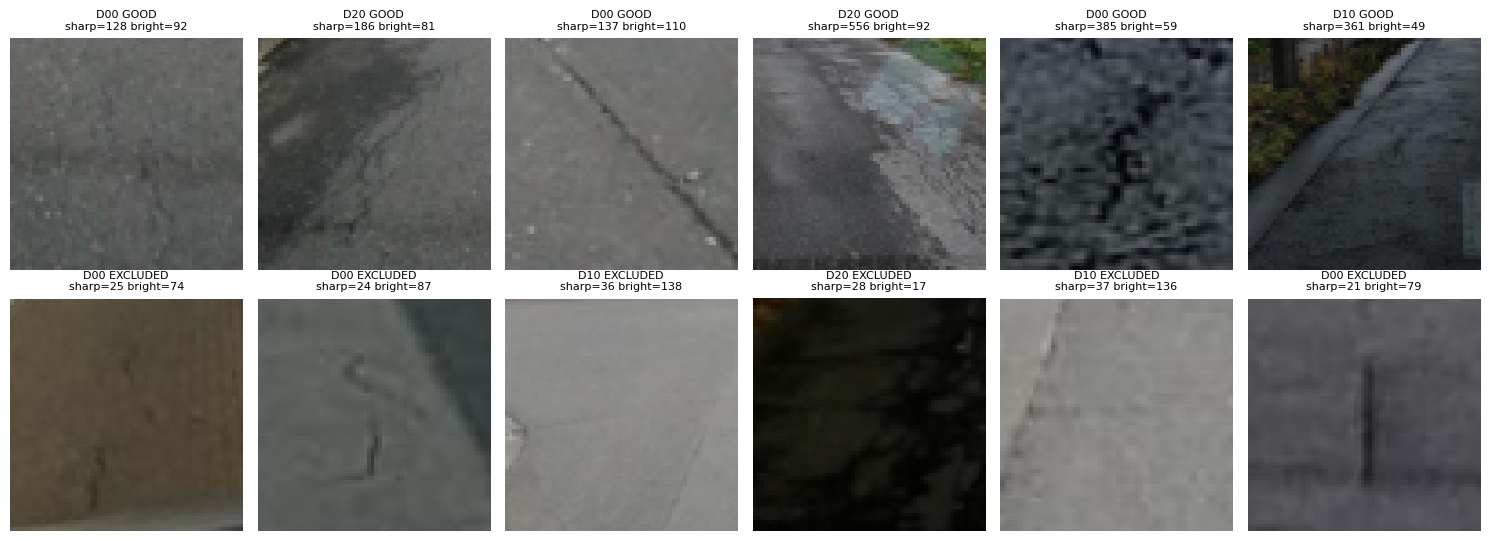

/tmp/ipykernel_2472/520578150.py:101: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  "annotated photos in full training folders": pd.Series(ds.full_counts, dtype="object").reindex(CLIST).fillna("n/a (streamed)"),


### Data counts, sampling and split
**Per-country counts:**

|               |   annotated photos in full training folders |   photos used |   patches |   good patches |   removed by quality filter (%) |
|:--------------|--------------------------------------------:|--------------:|----------:|---------------:|--------------------------------:|
| China         |                                        4378 |           219 |       539 |            520 |                             3.5 |
| Czech         |                                        2829 |           181 |       311 |            303 |                             2.6 |
| India         |                                        7706 |           234 |       553 |            451 |                            18.4 |
| Japan         |                                       10506 |           250 |       565 |            554 |                             1.9 |
| Norway        |                                        8161 |           197 |       704 |            544 |                            22.7 |
| United_States |                                        4805 |           220 |       573 |            571 |                             0.3 |

**Photo kinds among the annotation files read (the data-quality table).** `cand_damage` = photo with at least one damage box of >= 32px; `cand_empty` = annotation file lists NO object at all; `cand_other` = annotations exist but none qualifies (tiny boxes or non-damage labels), so the photo is not used for Background. Also read failures and skipped boxes:

| country       |   xml_requested |   xml_read_failed |   xml_unparsable |   no_matching_photo |   bad_boxes |   cand_damage |   cand_empty |   cand_other |   used_damage |   used_empty |   photo_fetch_failed |
|:--------------|----------------:|------------------:|-----------------:|--------------------:|------------:|--------------:|-------------:|-------------:|--------------:|-------------:|---------------------:|
| Japan         |             450 |                 0 |                0 |                   0 |           0 |           345 |           32 |           73 |           220 |           30 |                    0 |
| India         |             450 |                 0 |                0 |                   0 |           0 |           204 |          220 |           26 |           204 |           30 |                    0 |
| Czech         |             450 |                 0 |                0 |                   0 |           0 |           151 |          297 |            2 |           151 |           30 |                    0 |
| Norway        |             450 |                 0 |                0 |                   0 |           0 |           170 |          280 |            0 |           170 |           30 |                    3 |
| United_States |             450 |                 0 |                0 |                   0 |           0 |           449 |            0 |            1 |           220 |            0 |                    0 |
| China         |             450 |                 1 |                0 |                   0 |           0 |           398 |            0 |           51 |           220 |            0 |                    1 |

**Patch source (damage boxes vs the two Background origins):**

| country       |   bg_from_damage_photo |   bg_from_empty_photo |   damage_box |
|:--------------|-----------------------:|----------------------:|-------------:|
| China         |                     77 |                     0 |          462 |
| Czech         |                     42 |                    30 |          239 |
| India         |                     79 |                    30 |          444 |
| Japan         |                     87 |                    30 |          448 |
| Norway        |                     62 |                    30 |          612 |
| United_States |                     77 |                     0 |          496 |

**Quality filter:** blur threshold = Laplacian variance **37.1** (10th percentile of TRAINING-split damage patches). 2,943 of 3,245 patches are good.

**Removed by the filter, per class:**

| label      |   patches |   good |   removed (%) |
|:-----------|----------:|-------:|--------------:|
| D00        |      1398 |   1234 |          11.7 |
| D10        |       544 |    520 |           4.4 |
| D20        |       442 |    428 |           3.2 |
| D40        |       317 |    243 |          23.3 |
| Background |       544 |    518 |           4.8 |

**Duplicates:** 3 exact duplicate patches; 0 duplicate groups appear in more than one split. Leakage check (no photo in two splits): **passed**.

**Split (once, seed 42, by photo, inside each country), ALL patches:**

| split   |   D00 |   D10 |   D20 |   D40 |   Background |
|:--------|------:|------:|------:|------:|-------------:|
| train   |   968 |   391 |   305 |   221 |          386 |
| val     |   213 |    75 |    79 |    47 |           73 |
| test    |   217 |    78 |    58 |    49 |           85 |

**Same split, GOOD patches only (what training can use):**

| split   |   D00 |   D10 |   D20 |   D40 |   Background |
|:--------|------:|------:|------:|------:|-------------:|
| train   |   856 |   376 |   294 |   161 |          367 |
| val     |   185 |    71 |    78 |    39 |           68 |
| test    |   193 |    73 |    56 |    43 |           83 |

Training uses 2,054 good patches; validation 487 and test 487 keep every patch (unfiltered).

In [16]:
ds = prepare_dataset(X, meta, boxes_df, full_counts, sampling_df, rep)  # the split is created here, once

## Stage 3: Exploratory analysis (box shape, class balance)

Box shape separates the classes. Transverse cracks (D10) are wide and thin (median aspect **5.2**), longitudinal cracks (D00) are tall (median aspect **0.63**), and alligator cracks (D20) and potholes (D40) are closer to square (1.3 and 1.6). This is why we classify a square crop of each box.

Class balance is uneven: D00 **1,398**, D10 **544**, D20 **442**, D40 **317**, Background **544** (largest/smallest = **4.4x**), handled with balanced class weights (SVM, RF) and square-root inverse-frequency weights (CNN). Country mix is also uneven: India has only **4** D10 patches but **207** potholes, while the US has only **3** potholes and Norway is mostly D00 (468). This matters for the held-out results later, because per-class scores for some countries rest on very few patches.

[figure saved] /content/teamz_outputs/fig_box_shape_per_class.png


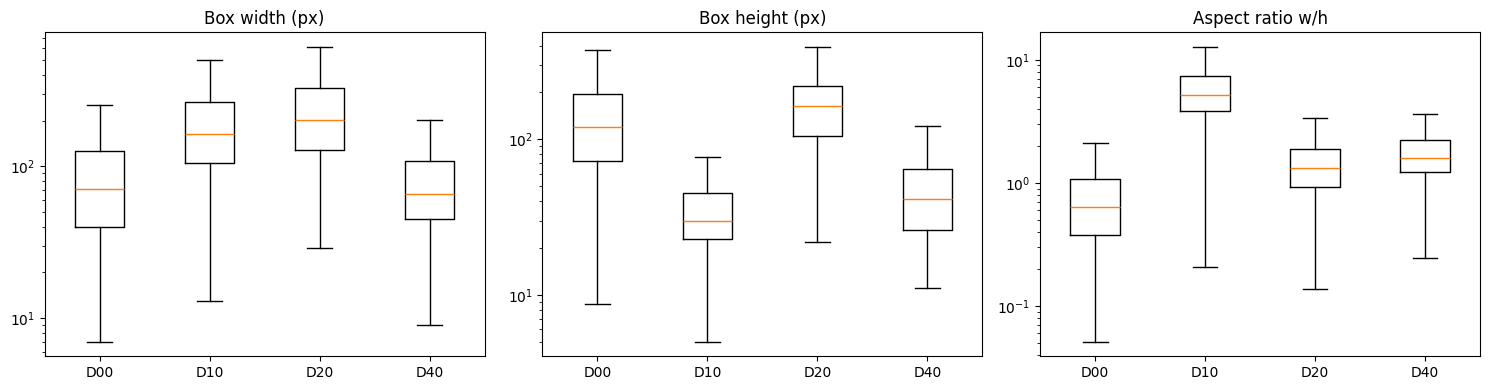

[figure saved] /content/teamz_outputs/fig_class_balance.png


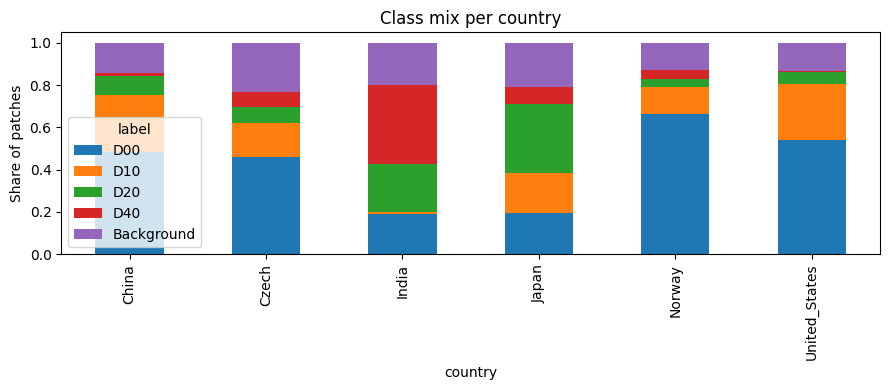

[figure saved] /content/teamz_outputs/fig_samples_by_country.png


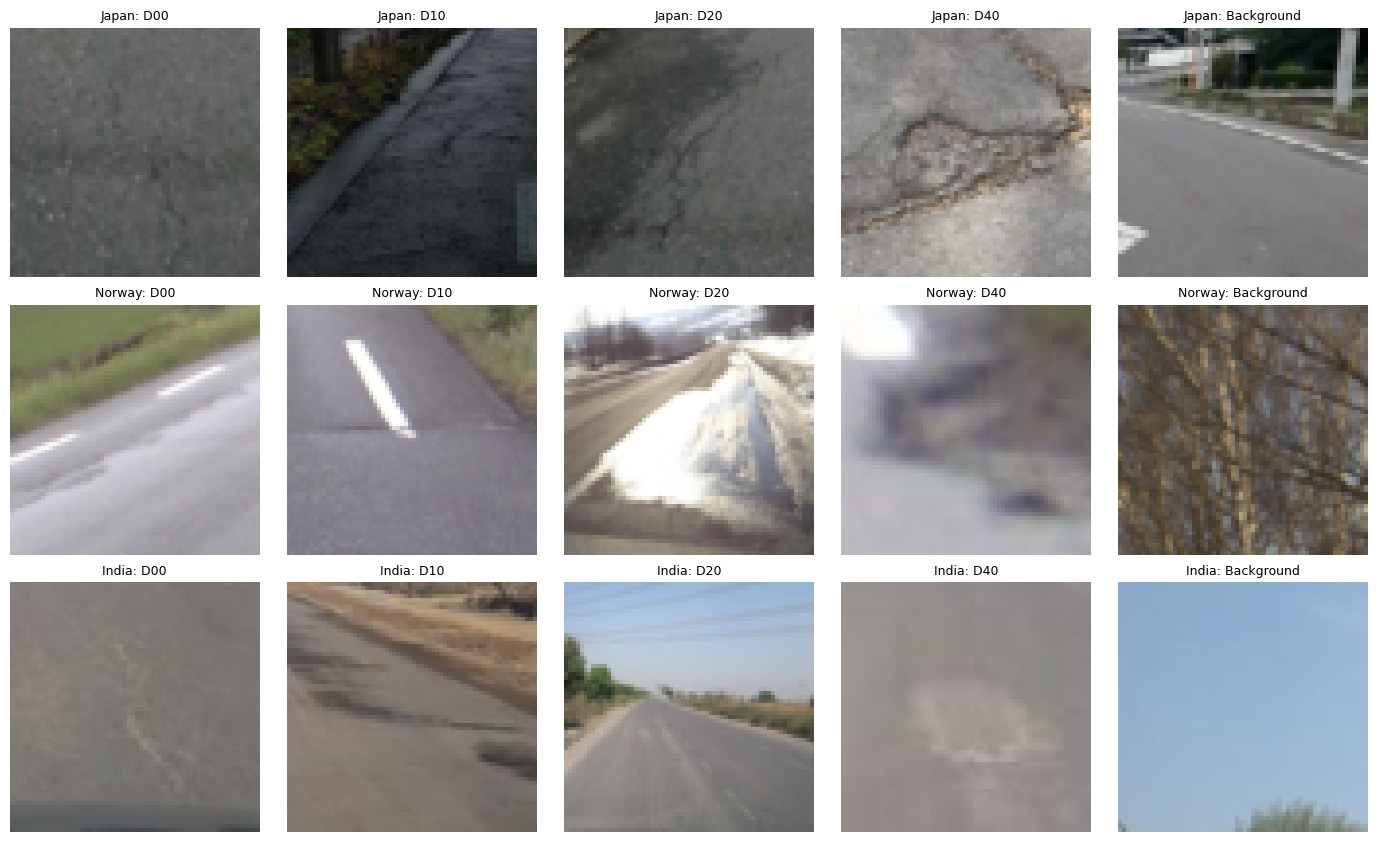

### Box shape and class balance
**Box geometry per damage class (from 3,912 annotated damage boxes in the photos read, all pixels):**

| cls   |    n |   median_w |   median_h |   median_aspect |   p10_aspect |   p90_aspect |
|:------|-----:|-----------:|-----------:|----------------:|-------------:|-------------:|
| D00   | 2009 |      71    |     120.13 |            0.63 |         0.22 |         1.64 |
| D10   |  882 |     164    |      30    |            5.22 |         2.72 |        10.52 |
| D20   |  620 |     201.08 |     164    |            1.32 |         0.7  |         2.88 |
| D40   |  401 |      66    |      41    |            1.6  |         0.91 |         2.95 |

**Patch counts per country and class (all patches):**

| country       |   D00 |   D10 |   D20 |   D40 |   Background |
|:--------------|------:|------:|------:|------:|-------------:|
| China         |   261 |   145 |    49 |     7 |           77 |
| Czech         |   143 |    50 |    23 |    23 |           72 |
| India         |   105 |     4 |   128 |   207 |          109 |
| Japan         |   111 |   105 |   185 |    47 |          117 |
| Norway        |   468 |    88 |    26 |    30 |           92 |
| United_States |   310 |   152 |    31 |     3 |           77 |

**Class totals:** D00: 1,398, D10: 544, D20: 442, D40: 317, Background: 544. Overall imbalance (largest / smallest class): **4.4x**, handled with balanced class weights (SVM, RF) and square-root inverse-frequency weights (CNN).

In [17]:
counts = run_eda(ds, rep)

## Stage 4: Classical baselines (HOG + SVM / RF, shape-only)

HOG features (1,764 dimensions) feed a LinearSVC and a Random Forest. Validation selected **C = 0.001** (macro-F1 0.455) and `min_samples_leaf = 3`. On the pooled test set the classical models are weak: **HOG+SVM 0.392** and **HOG+RF 0.348** macro-F1. Alligator cracks (D20) are the hardest class (F1 0.21). Within-country SVMs average **0.410**, with India the best at 0.620.

A shape-only random forest that sees **only box width/height, no pixels**, reaches **0.796** (5-class) and **0.746** (4-class damage-only). The 5-class figure is upper-biased because Background 'boxes' are our own sampled squares, so the 4-class value is the one to quote. It shows that box geometry alone is a strong cue for damage type, stronger than HOG pixel features.

In [18]:
base = run_baselines(ds, rep)

HOG features: (3245, 1764) (5s)


### Classical baselines
HOG feature length **1764**.
**LinearSVC validation macro-F1 by C:** C=0.001: 0.455, C=0.01: 0.397, C=0.1: 0.392 -> chosen **C=0.001**.
**Random Forest validation macro-F1 by min_samples_leaf:** 1: 0.311, 3: 0.388 -> chosen **3**.

**Pooled test (all six countries seen in training) macro-F1:** HOG+SVM **0.392**, HOG+RF **0.348**.
**Shape-only RF (box geometry, no pixels):** 5-class **0.796** (upper-biased: for Background the 'box' is our sampled square); 4-class damage-only **0.746** (no Background, clean of the sampling artefact).

**Within-country HOG+SVM macro-F1 (train and test inside one country, C=0.001):** Japan: 0.388, India: 0.620, Czech: 0.368, Norway: 0.334, United_States: 0.410, China: 0.339; mean **0.410**.

**HOG+SVM per-class report (pooled test):**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| D00          |       0.63  |    0.502 |      0.559 |   217     |
| D10          |       0.359 |    0.359 |      0.359 |    78     |
| D20          |       0.189 |    0.241 |      0.212 |    58     |
| D40          |       0.39  |    0.469 |      0.426 |    49     |
| Background   |       0.369 |    0.447 |      0.404 |    85     |
| accuracy     |       0.435 |    0.435 |      0.435 |     0.435 |
| macro avg    |       0.387 |    0.404 |      0.392 |   487     |
| weighted avg |       0.464 |    0.435 |      0.445 |   487     |

## Stage 5: MobileNetV2, pooled protocol

An ImageNet-pretrained MobileNetV2 (2.23M parameters, 96x96 input, 5 epochs, AdamW, cosine schedule, class-weighted loss) was fine-tuned on 2,054 good training patches. The learning rate was chosen on validation photos only: **lr = 0.001** (val macro-F1 0.759, against 0.708 at 3e-4 and 0.615 at 1e-4). Validation F1 was still rising at epoch 5 (0.742 to 0.759), so the model may be slightly under-trained.

Pooled test macro-F1 is **0.693** (seed 42), and **0.695 +/- 0.008** over three seeds (0.693, 0.686, 0.706). This is well above HOG+SVM (0.392) and HOG+RF (0.348), so learned features help a great deal over hand-crafted HOG here.

device: cuda | input size: 96
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 143MB/s]


[figure saved] /content/teamz_outputs/fig_training_curve.png


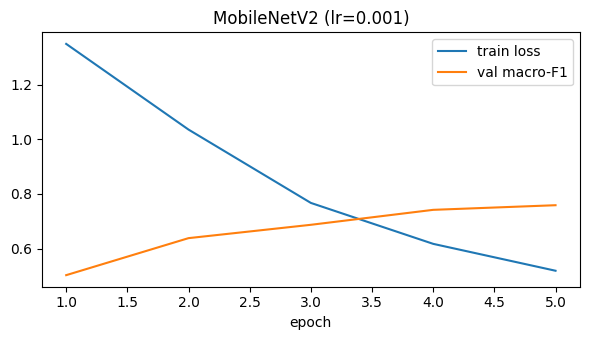

### Deep learning (MobileNetV2), pooled protocol
**Architecture:** MobileNetV2 (ImageNet weights), 2.23M parameters, input 96x96, batch 64, 5 epochs, AdamW (wd 1e-4), cosine schedule, class-weighted cross-entropy, device cuda. Trained on 2,054 good training patches.

**Learning-rate search (pooled validation photos only, seed 42):**

|     lr |   best_val_macro_f1 |   best_epoch |
|-------:|--------------------:|-------------:|
| 0.001  |              0.7589 |            5 |
| 0.0003 |              0.7083 |            5 |
| 0.0001 |              0.6152 |            4 |

Chosen **lr = 0.001** (search took 0.9 min including extra seeds).

**Training history of the chosen run:**

|   epoch |   train_loss |   val_macro_f1 |
|--------:|-------------:|---------------:|
|       1 |       1.3491 |         0.503  |
|       2 |       1.0356 |         0.6385 |
|       3 |       0.7673 |         0.6873 |
|       4 |       0.6176 |         0.742  |
|       5 |       0.5192 |         0.7589 |

**Pooled test macro-F1 (all countries seen in training):** CNN **0.693** (primary seed) vs HOG+SVM 0.392 vs HOG+RF 0.348.
**CNN over seeds [42, 43, 44]:** 0.693, 0.686, 0.706 -> mean **0.695**, sd 0.008.

In [19]:
runner = CNNRunner(ds.X, ds.y)
pooled = run_pooled(ds, runner, base, rep)

## Stage 6: Leave-one-country-out (hyperparameters re-selected in every fold)

Each fold trains on the five other countries, selects the learning rate, SVM C and checkpoint on those countries' validation photos, and is tested on every patch of the held-out country. The table of protocols shows that pooled and LOCO are **different experiments** (LOCO also trains on the other countries' test-split photos), so the two are compared on the same test-split patches in the next stage. The learning rate search chose **lr = 0.001** and **C = 0.001** in all six folds, so the held-out country never influenced those choices.

Held-out macro-F1 (SVM / CNN): Japan 0.352 / 0.608, India 0.308 / 0.400, Czech 0.361 / 0.590, Norway 0.298 / 0.406, United States 0.298 / 0.633, China 0.240 / 0.471. The CNN beats the SVM in every fold.

In [20]:
loco = run_loco(ds, runner, base, rep)

Japan: held-out n=565  SVM F1=0.352  CNN F1=0.608  (1.5 min)
India: held-out n=553  SVM F1=0.308  CNN F1=0.400  (3.3 min)
Czech: held-out n=311  SVM F1=0.361  CNN F1=0.590  (4.9 min)
Norway: held-out n=704  SVM F1=0.298  CNN F1=0.406  (6.4 min)
United_States: held-out n=573  SVM F1=0.298  CNN F1=0.633  (7.9 min)
China: held-out n=539  SVM F1=0.240  CNN F1=0.471  (9.5 min)


### Protocols compared (they are different experiments)
The pooled model trains on good patches of the **training** photos of all six countries and is tested on the **test** photos. Each LOCO fold trains on good patches of the **training and test** photos of the five other countries, selects its learning rate, C and checkpoint on those countries' **validation** photos, and is tested on **every** patch of the held-out country. To compare seen and unseen on identical patches, the held-out country's test-split patches are also scored separately below.

| country_held_out   |   train_patches |   val_patches |   heldout_patches |   heldout_test_split_patches |   svm_C |   cnn_lr |   best_val_macro_f1 |
|:-------------------|----------------:|--------------:|------------------:|-----------------------------:|--------:|---------:|--------------------:|
| (pooled model)     |            2054 |           487 |               487 |                          487 |   0.001 |  nan     |            nan      |
| Japan              |            2029 |           405 |               565 |                           85 |   0.001 |    0.001 |              0.7468 |
| India              |            2127 |           398 |               553 |                           93 |   0.001 |    0.001 |              0.7568 |
| Czech              |            2244 |           441 |               311 |                           41 |   0.001 |    0.001 |              0.7635 |
| Norway             |            2016 |           401 |               704 |                          106 |   0.001 |    0.001 |              0.7588 |
| United_States      |            2030 |           387 |               573 |                           85 |   0.001 |    0.001 |              0.7689 |
| China              |            2064 |           403 |               539 |                           77 |   0.001 |    0.001 |              0.785  |

**Learning-rate search inside each LOCO fold (validation macro-F1 on the five other countries):**

| country_held_out   |   0.0001 |   0.0003 |   0.001 |
|:-------------------|---------:|---------:|--------:|
| China              |   0.6545 |   0.7167 |  0.785  |
| Czech              |   0.6691 |   0.7454 |  0.7635 |
| India              |   0.6876 |   0.7379 |  0.7568 |
| Japan              |   0.6433 |   0.7295 |  0.7468 |
| Norway             |   0.6899 |   0.727  |  0.7588 |
| United_States      |   0.6685 |   0.711  |  0.7689 |

## Stage 7: Results tables and figures

**Headline:** on unseen countries the CNN averages **0.518** macro-F1 (seed mean 0.507), against **0.310** for HOG+SVM. Seen-country performance for the CNN is **0.613** (mean of per-country slices of the pooled test), so unseen countries cost about **0.11** macro-F1 on matched patches (0.095 on all patches).

The drop is not uniform. Czech (0.264), India (0.187) and Japan (0.112) lose the most; **United States gains slightly (-0.051)**, probably because its patches are mostly D00/D10 and its Background is easy. **India is the hardest** unseen country (0.400, 95% photo-level CI 0.367-0.439) and the **United States the easiest** (0.633, CI 0.565-0.722). Seed spread is small (sd 0.003-0.03), but the bootstrap intervals are wide, especially for Czech (0.529-0.643), where only 41 test-split patches exist. Differences between neighbouring countries should therefore not be over-interpreted.

**Shape-only vs the network.** On damage-only macro-F1 the shape-only RF (pooled 0.746, LOCO 0.539) **matches or beats MobileNetV2** (0.702 pooled, 0.499 LOCO); the CNN wins only in the United States and China. Both beat HOG+SVM (0.414 / 0.315) clearly. So the CNN's advantage over classical features is real, but it does **not** beat a model that sees only box geometry. That is an important caveat: the geometry cue depends on having a box in the first place, which a patch classifier in deployment would not have.

[figure saved] /content/teamz_outputs/fig_loco_f1.png


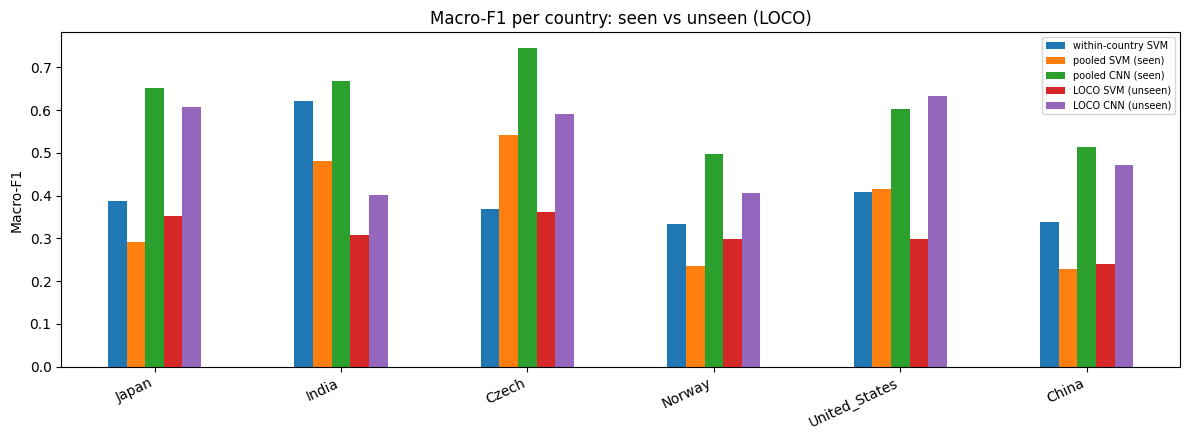

### Leave-one-country-out results
**Macro-F1 per country** (row = the country held out in the LOCO columns). Intervals are 95% **photo-level** bootstrap (300 resamples of whole photos) for the LOCO CNN on all held-out patches. 'seed mean/sd' is over seeds [42, 43, 44].

|               |   within-country SVM |   pooled SVM (seen) |   pooled CNN (seen) |   LOCO SVM (unseen) |   LOCO CNN (unseen) |   LOCO CNN (unseen, test-split patches only) |   LOCO CNN seed mean |   LOCO CNN seed sd |   CI low |   CI high |   LOCO shape-only RF (5-class, biased) |   LOCO shape-only RF (4-class damage) |   n held-out patches |   n test-split patches |
|:--------------|---------------------:|--------------------:|--------------------:|--------------------:|--------------------:|---------------------------------------------:|---------------------:|-------------------:|---------:|----------:|---------------------------------------:|--------------------------------------:|---------------------:|-----------------------:|
| Japan         |                0.388 |               0.292 |               0.652 |               0.352 |               0.608 |                                        0.54  |                0.609 |              0.009 |    0.566 |     0.65  |                                  0.711 |                                 0.636 |                  565 |                     85 |
| India         |                0.62  |               0.48  |               0.669 |               0.308 |               0.4   |                                        0.482 |                0.388 |              0.012 |    0.367 |     0.439 |                                  0.547 |                                 0.402 |                  553 |                     93 |
| Czech         |                0.368 |               0.542 |               0.745 |               0.361 |               0.59  |                                        0.48  |                0.591 |              0.008 |    0.529 |     0.643 |                                  0.727 |                                 0.667 |                  311 |                     41 |
| Norway        |                0.334 |               0.236 |               0.496 |               0.298 |               0.406 |                                        0.386 |                0.405 |              0.003 |    0.362 |     0.45  |                                  0.559 |                                 0.423 |                  704 |                    106 |
| United_States |                0.41  |               0.417 |               0.602 |               0.298 |               0.633 |                                        0.653 |                0.591 |              0.03  |    0.565 |     0.722 |                                  0.652 |                                 0.581 |                  573 |                     85 |
| China         |                0.339 |               0.228 |               0.514 |               0.24  |               0.471 |                                        0.459 |                0.46  |              0.017 |    0.409 |     0.526 |                                  0.616 |                                 0.522 |                  539 |                     77 |

**Mean over the six countries:** LOCO CNN **0.518** (seed mean 0.507), LOCO SVM 0.310, pooled CNN (seen) 0.613, within-country SVM 0.410, LOCO shape-only 5-class 0.635, 4-class damage-only 0.539.

**Transfer gap, seen minus unseen CNN.** `gap (matched)` compares the SAME test-split patches (the fair comparison); `gap (all patches)` compares seen-on-test-split with unseen-on-all-patches.

|               |   gap (matched) |   gap (all patches) |
|:--------------|----------------:|--------------------:|
| Japan         |           0.112 |               0.044 |
| India         |           0.187 |               0.268 |
| Czech         |           0.264 |               0.155 |
| Norway        |           0.111 |               0.091 |
| United_States |          -0.051 |              -0.031 |
| China         |           0.055 |               0.043 |

Mean matched gap **0.113**, mean all-patch gap 0.095. Hardest country (unseen CNN): **India**; easiest: **United_States**. Total LOCO time 9.5 min.

### Damage-only comparison (macro-F1 over D00, D10, D20, D40; Background predictions count as misses)
|                         |   pooled test (seen) |   LOCO mean (unseen) |
|:------------------------|---------------------:|---------------------:|
| HOG+SVM                 |                0.414 |                0.315 |
| MobileNetV2             |                0.702 |                0.499 |
| Shape-only RF (4-class) |                0.746 |                0.539 |

**Per held-out country (LOCO):**

|               |   HOG+SVM |   MobileNetV2 |   Shape-only RF (4-class) |
|:--------------|----------:|--------------:|--------------------------:|
| Japan         |     0.358 |         0.582 |                     0.636 |
| India         |     0.276 |         0.343 |                     0.402 |
| Czech         |     0.395 |         0.53  |                     0.667 |
| Norway        |     0.312 |         0.399 |                     0.423 |
| United_States |     0.269 |         0.588 |                     0.581 |
| China         |     0.277 |         0.552 |                     0.522 |

This removes the Background sampling artefact from the shape-only model, so the gap between it and the pixel models is the honest value of box geometry on annotated damage.

In [21]:
res, hardest, easiest = loco_results(ds, base, pooled, loco, rep)
dmg_tab = damage_only_table(ds, base, pooled, loco, rep)

## Stage 8: Error analysis, threshold sensitivity, error costs

**Per class (all held-out predictions pooled).** D00 is best (F1 0.70), then Background (0.62) and D10 (0.55). **D20 (0.35) and D40 (0.43) are weakest.** The most common confusions are D00 -> Background (198), D00 -> D20 (129), D20 -> D00 (119) and D20 -> D10 (100). The twelve most confident mistakes are mostly D00 or D20 boxes called Background with confidence above 0.99, from China, Norway and Japan, so the confidence score is not a reliable warning for unseen countries.

**Background sampling check.** Background recall is **0.726** for patches taken from damage photos and **0.758** from empty photos, so the model does not appear to be relying heavily on where a Background patch came from. China is the exception: Background recall is only **0.312** (false-alarm rate 0.688), and China has no empty photos to compare against.

**Error costs.** Missing real damage is worst in **Norway (28.3%)**, then China (16.5%) and India (12.6%); false alarms are highest in **China (68.8%)**. Pothole recall is 0.29 in India and 1.0 in the United States, but the US has only 3 potholes, so that value is not reliable.

**Threshold sensitivity.** Raising the Background probability threshold trades missed damage against false alarms: at 0.5 about 9.8% of damage is missed with 29.8% false alarms; at 0.2, 19.3% missed with 19.7% false alarms. This is a **sensitivity analysis on test predictions, not a tuned operating point**. For a road-safety setting a missed hazard is usually the costlier error, but the right threshold must be set on separate validation data and checked per country, since Norway and China behave very differently. Country is the only subgroup available; the data has no road type, weather or camera labels.

[figure saved] /content/teamz_outputs/fig_confusion_cnn.png


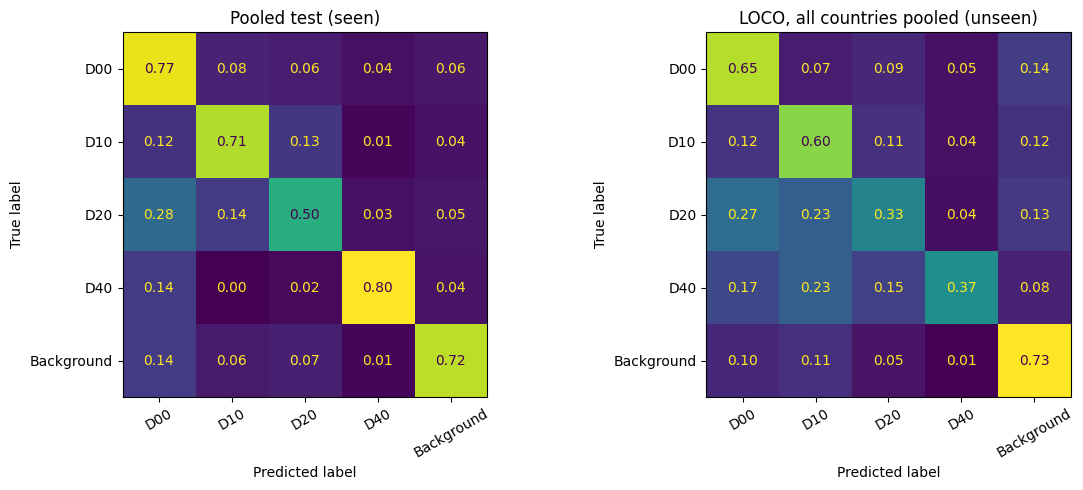

[figure saved] /content/teamz_outputs/fig_error_examples.png


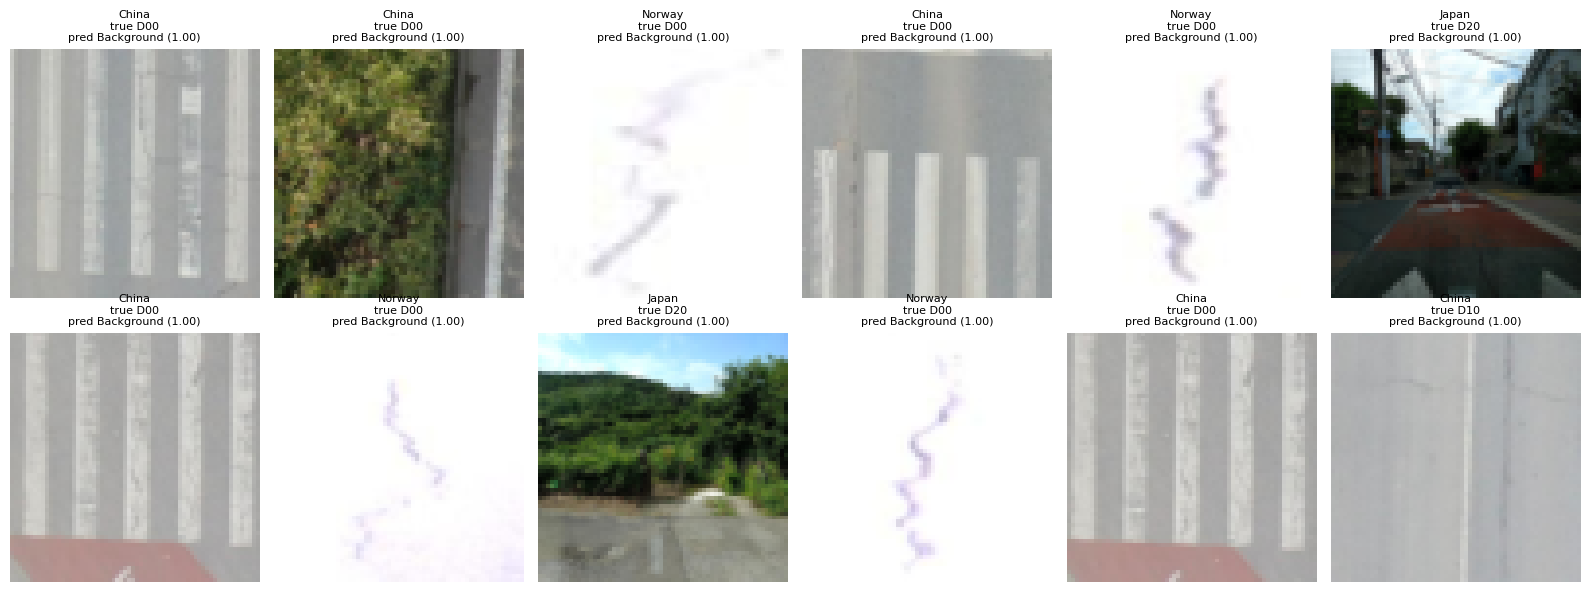

### Per-class results and error analysis (LOCO CNN)
**Recall per class for each held-out country:**

|               |   D00 |   D10 |   D20 |   D40 |   Background |
|:--------------|------:|------:|------:|------:|-------------:|
| Japan         | 0.901 | 0.705 | 0.308 | 0.489 |        0.778 |
| India         | 0.629 | 0.5   | 0.25  | 0.29  |        0.743 |
| Czech         | 0.497 | 0.64  | 0.652 | 0.522 |        0.819 |
| Norway        | 0.5   | 0.364 | 0.308 | 0.533 |        0.87  |
| United_States | 0.894 | 0.651 | 0.258 | 1     |        0.831 |
| China         | 0.628 | 0.621 | 0.571 | 0.571 |        0.312 |

**Per-class report, all held-out predictions pooled:**

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| D00          |       0.758 |    0.652 |      0.701 |  1398     |
| D10          |       0.5   |    0.605 |      0.547 |   544     |
| D20          |       0.357 |    0.335 |      0.346 |   442     |
| D40          |       0.52  |    0.372 |      0.434 |   317     |
| Background   |       0.537 |    0.733 |      0.62  |   544     |
| accuracy     |       0.587 |    0.587 |      0.587 |     0.587 |
| macro avg    |       0.534 |    0.54  |      0.53  |  3245     |
| weighted avg |       0.6   |    0.587 |      0.587 |  3245     |

**Five most frequent confusions (true -> predicted):** D00 -> Background (198); D00 -> D20 (129); D20 -> D00 (119); D20 -> D10 (100); D00 -> D10 (96).

**Background recall by how the patch was sampled (LOCO).** A large gap suggests the model partly learned the patch's origin:

| source               |   patches |   recall |
|:---------------------|----------:|---------:|
| bg_from_damage_photo |       424 |    0.726 |
| bg_from_empty_photo  |       120 |    0.758 |

|                                           |   patches |   recall |
|:------------------------------------------|----------:|---------:|
| ('China', 'bg_from_damage_photo')         |        77 |    0.312 |
| ('Czech', 'bg_from_damage_photo')         |        42 |    0.833 |
| ('Czech', 'bg_from_empty_photo')          |        30 |    0.8   |
| ('India', 'bg_from_damage_photo')         |        79 |    0.81  |
| ('India', 'bg_from_empty_photo')          |        30 |    0.567 |
| ('Japan', 'bg_from_damage_photo')         |        87 |    0.782 |
| ('Japan', 'bg_from_empty_photo')          |        30 |    0.767 |
| ('Norway', 'bg_from_damage_photo')        |        62 |    0.855 |
| ('Norway', 'bg_from_empty_photo')         |        30 |    0.9   |
| ('United_States', 'bg_from_damage_photo') |        77 |    0.831 |

**Twelve most confident wrong predictions on unseen countries** (`fig_error_examples.png`):

| country   | true   | predicted   |   confidence | source     |
|:----------|:-------|:------------|-------------:|:-----------|
| China     | D00    | Background  |        1     | damage_box |
| China     | D00    | Background  |        1     | damage_box |
| Norway    | D00    | Background  |        0.999 | damage_box |
| China     | D00    | Background  |        0.999 | damage_box |
| Norway    | D00    | Background  |        0.999 | damage_box |
| Japan     | D20    | Background  |        0.999 | damage_box |
| China     | D00    | Background  |        0.998 | damage_box |
| Norway    | D00    | Background  |        0.998 | damage_box |
| Japan     | D20    | Background  |        0.998 | damage_box |
| Norway    | D00    | Background  |        0.998 | damage_box |
| China     | D00    | Background  |        0.998 | damage_box |
| China     | D10    | Background  |        0.997 | damage_box |

[figure saved] /content/teamz_outputs/fig_threshold_tradeoff.png


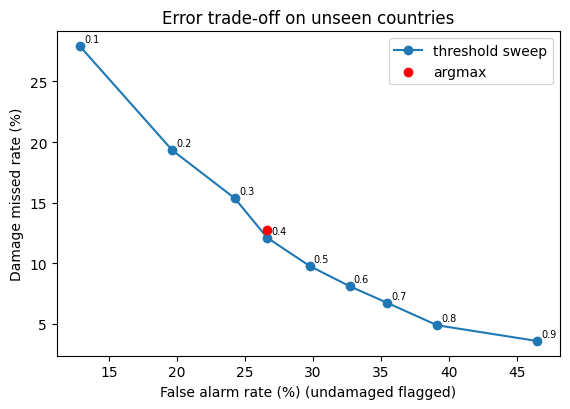

### Threshold sensitivity (unseen countries, all folds pooled)
| rule                              |   damage_missed_FN |   false_alarm_FP |
|:----------------------------------|-------------------:|-----------------:|
| P(Background) >= 0.1 -> undamaged |              0.279 |            0.129 |
| P(Background) >= 0.2 -> undamaged |              0.193 |            0.197 |
| P(Background) >= 0.3 -> undamaged |              0.154 |            0.243 |
| P(Background) >= 0.4 -> undamaged |              0.121 |            0.267 |
| P(Background) >= 0.5 -> undamaged |              0.098 |            0.298 |
| P(Background) >= 0.6 -> undamaged |              0.081 |            0.327 |
| P(Background) >= 0.7 -> undamaged |              0.067 |            0.355 |
| P(Background) >= 0.8 -> undamaged |              0.049 |            0.392 |
| P(Background) >= 0.9 -> undamaged |              0.036 |            0.465 |
| argmax (what the model uses now)  |              0.127 |            0.267 |

**Per country at two thresholds (FN = damage missed, FP = false alarm):**

|                        |    FN |    FP |
|:-----------------------|------:|------:|
| ('Japan', 0.5)         | 0.04  | 0.231 |
| ('Japan', 0.2)         | 0.105 | 0.179 |
| ('India', 0.5)         | 0.063 | 0.303 |
| ('India', 0.2)         | 0.223 | 0.193 |
| ('Czech', 0.5)         | 0.008 | 0.194 |
| ('Czech', 0.2)         | 0.054 | 0.181 |
| ('Norway', 0.5)        | 0.239 | 0.185 |
| ('Norway', 0.2)        | 0.391 | 0.065 |
| ('United_States', 0.5) | 0.008 | 0.169 |
| ('United_States', 0.2) | 0.044 | 0.091 |
| ('China', 0.5)         | 0.143 | 0.753 |
| ('China', 0.2)         | 0.221 | 0.506 |

This is a sensitivity analysis, not a tuned operating point (see the docstring).

### Error costs per held-out country (LOCO CNN, argmax rule)
Damage missed = real damage predicted as Background (unsafe road left unrepaired); false alarm = undamaged road flagged (wasted inspection):

|               |   damage missed (FN) rate |   false alarm (FP) rate |   pothole recall |   n_damage |   n_pothole |   n_background |
|:--------------|--------------------------:|------------------------:|-----------------:|-----------:|------------:|---------------:|
| Japan         |                     0.056 |                   0.222 |            0.489 |        448 |          47 |            117 |
| India         |                     0.126 |                   0.257 |            0.29  |        444 |         207 |            109 |
| Czech         |                     0.017 |                   0.181 |            0.522 |        239 |          23 |             72 |
| Norway        |                     0.283 |                   0.13  |            0.533 |        612 |          30 |             92 |
| United_States |                     0.02  |                   0.169 |            1     |        496 |           3 |             77 |
| China         |                     0.165 |                   0.688 |            0.571 |        462 |           7 |             77 |

Subgroup note: country is the only subgroup the data allows; nothing in the data labels road type, weather or camera, so claims are limited to country-level transfer.

In [22]:
err = error_analysis(ds, pooled, loco, rep)
thr_tab = threshold_analysis(ds, loco, rep)
risk = error_costs(ds, loco, rep)

## Stage 9: Prototype

The prototype classifies a **region the user selects**; it does not find damage in a whole photo (that would need a detector in front of it). The demo figure shows boxes coloured by predicted class on photos from countries the scoring model never saw. As an example, `classify_crop()` on a Norwegian patch returned Transverse crack **0.939**. Given the confident errors in Stage 8, the prototype should show these probabilities as advisory and not as a decision.

[figure saved] /content/teamz_outputs/fig_prototype_demo.png


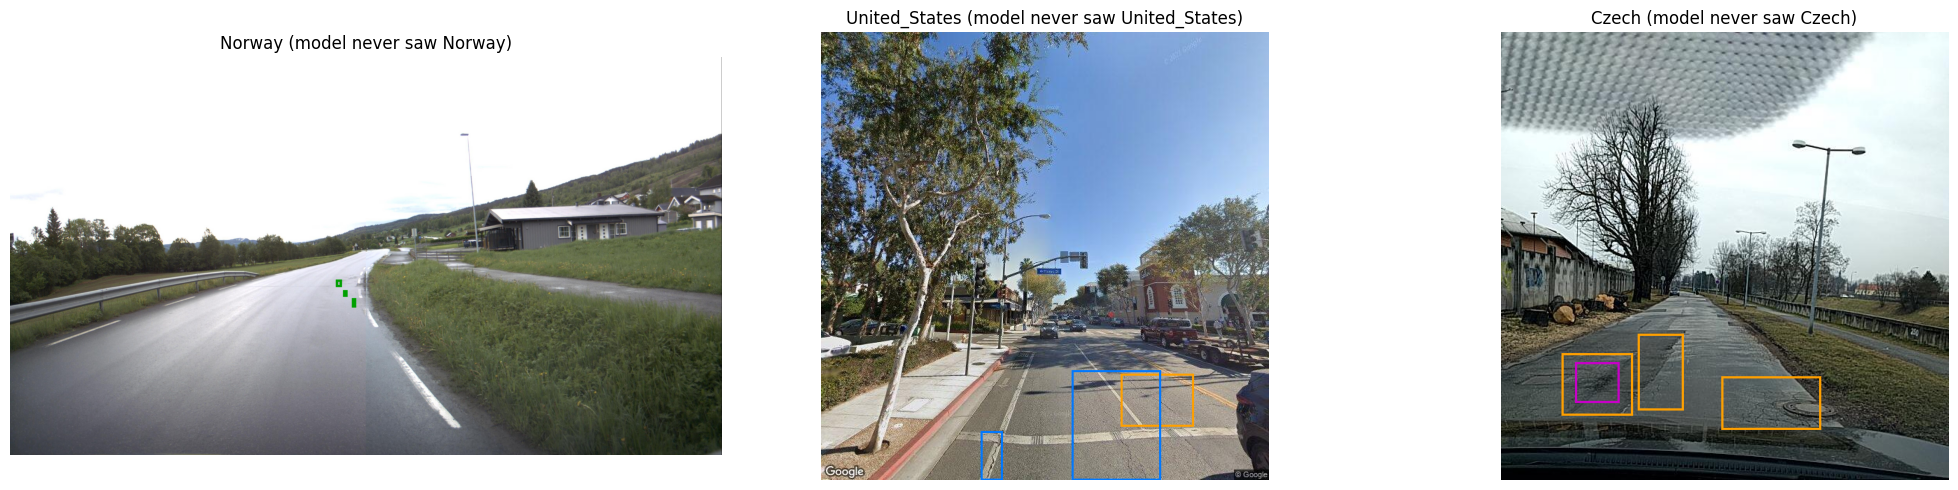

/tmp/ipykernel_2472/2287033950.py:55: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  x = torch.from_numpy(arr).to(self.dev).permute(0, 3, 1, 2).float() / 255.


### Prototype
`fig_prototype_demo.png` shows boxes coloured by predicted class (red longitudinal, blue transverse, orange alligator, purple pothole, green background) on photos from countries the scoring model never saw. Example `classify_crop()` output on one Norwegian patch: {'Longitudinal crack': 0.015, 'Transverse crack': 0.939, 'Alligator crack': 0.008, 'Pothole': 0.0, 'Undamaged road': 0.039}

In [23]:
run_prototype(ds, runner, loco, rep, with_demo=True)

## Stage 10: Headline numbers and download

Final numbers (also saved in `results.json` and `report_numbers.md`): 3,245 patches; split 2,271 / 487 / 487; 2,943 good, 2,054 used for pooled training. Pooled macro-F1: **CNN 0.693** (0.695 +/- 0.008 over seeds), HOG+SVM 0.392, HOG+RF 0.348, shape-only 0.796 (5-class, biased) / 0.746 (4-class). LOCO mean macro-F1: **CNN 0.518**, SVM 0.310.

**Main limitations.** (1) Small sample: about 1,300 photos, with only 3-4 country-class cells of fewer than 10 patches, so some per-class numbers are noisy. (2) One data split with three model seeds, so seed variance is captured but split variance is not. (3) China merges two capture setups. (4) The pooled and LOCO protocols train on different data, so they are compared only on matched test-split patches. (5) Training stopped at 5 epochs while validation F1 was still rising. (6) The shape-only model matches or beats the CNN, so conclusions about 'learned visual features' should be stated carefully.

In [24]:
results = write_results(ds, base, pooled, loco, res, risk, dmg_tab, rep)
import json, shutil
print(json.dumps({k: results[k] for k in ['n_patches','split_counts','n_good','n_train_good','pooled_f1','mean_loco_cnn','mean_loco_svm']}, indent=2, default=float))
shutil.make_archive('/content/teamz_results' if os.path.exists('/content') else 'teamz_results', 'zip', OUT)
try:
    from google.colab import files
    files.download('/content/teamz_results.zip')
except Exception:
    print('Results zipped next to the output folder (teamz_results.zip).')

[saved] /content/teamz_outputs/results.json
{
  "n_patches": 3245,
  "split_counts": {
    "train": 2271,
    "test": 487,
    "val": 487
  },
  "n_good": 2943,
  "n_train_good": 2054,
  "pooled_f1": {
    "svm": 0.39205023502895847,
    "rf": 0.34815958505522737,
    "cnn": 0.6931773424610425,
    "shape5": 0.795660276018916,
    "shape4": 0.7459552077985347,
    "cnn_seed_f1": [
      0.6931773424610425,
      0.6856922611277667,
      0.7055392427539331
    ]
  },
  "mean_loco_cnn": 0.5180608673648297,
  "mean_loco_svm": 0.3097492707568414
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>